# Exoplanet candidate classification (NASA Kepler KOI)
**CMPS 261 · Project 4.1 · Hend Albakour and Mohammad Hashem Al Beyrouthy**

Can machine learning tell real exoplanets from false positives using only measurements available **before** scientists vetted them? This notebook contains all the code, in the order of the project plan:

1. **P1**: Data audit, cleaning and split by star (Hend)
2. **P2 + P3**: Features, leakage check and Level 1 models (Mohamad)
3. **P4**: Level 2: neural network (Hend)
4. **P5**: Model comparison, one-time test and split sensitivity (Mohamad)
5. **P6**: Failure analysis and trust in confidence (Hend)
6. **P7**: Interpretability, complexity and the final model (Mohamad)

Run it from the `notebooks/` folder of the repository (Run All). Every part reads its inputs from the repository (`data/`, `features.py`, `results/`, `models/`), so the parts can also be run on their own. `random_state = 42` is used everywhere.

---
# P1 · Data audit, cleaning and split by star
*Owner: Hend · source notebook: `notebooks/P1_data_split.ipynb`*

# P1 · Data audit, cleaning and split
**Owner: Member A** · CMPS 261 Project 4.1 · Kepler Objects of Interest

What this notebook does:
1. Loads the full KOI cumulative table from the NASA Exoplanet Archive (downloads it the first time).
2. Audits it: class counts, how many KOIs share a star, % missing per feature.
3. Cleans it: drops duplicate `kepoi_name` and rows with non-positive period, duration, depth, planet radius or star radius. Missing values are **not** filled here (that happens inside the pipeline in P2).
4. Keeps CONFIRMED (label 1) and FALSE POSITIVE (label 0); saves CANDIDATE rows separately.
5. Lazy baseline: "everything is a false positive".
6. Splits 60 / 20 / 20 **by star** (`kepid`), checks no star is in two sets, and saves `data/processed/koi_split.csv`.

Outputs (shared names from the plan): `data/processed/koi_split.csv`, `data/processed/koi_candidates.csv`.

In [67]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# Works whether the notebook runs from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "koi_cumulative.csv"
PROCESSED = ROOT / "data" / "processed"
RAW.parent.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

SEED = 42
pd.set_option("display.max_rows", 80)
print("Repo root:", ROOT)

Repo root: c:\Users\Administrator\kepler-koi-classification


## 1. Load the data
The first run downloads **all columns** of the `cumulative` table through the archive's TAP service and saves it to `data/raw/koi_cumulative.csv`, plus the download date (needed for the README). Later runs reuse the saved file, so both members work on the same snapshot.

If the download fails (no internet / SSL error): open the [KOI cumulative table](https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=cumulative), choose **Download Table → CSV format, All Columns**, and save it as `data/raw/koi_cumulative.csv`. The loader below skips the `#` comment lines that the website adds.

In [68]:
URL = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
       "?query=select+*+from+cumulative&format=csv")

if not RAW.exists():
    print("Downloading the KOI cumulative table ...")
    pd.read_csv(URL, low_memory=False).to_csv(RAW, index=False)
    (RAW.parent / "DOWNLOAD_DATE.txt").write_text(str(pd.Timestamp.today().date()))

# Skip '#' comment lines at the top (present when downloaded from the website)
n_comment = 0
with open(RAW, encoding="utf-8") as f:
    for line in f:
        if not line.startswith("#"):
            break
        n_comment += 1
df = pd.read_csv(RAW, skiprows=n_comment, low_memory=False)

date_file = RAW.parent / "DOWNLOAD_DATE.txt"
print("Download date:", date_file.read_text() if date_file.exists() else "unknown (manual download: write the date in DOWNLOAD_DATE.txt)")
print("Shape:", df.shape)

Download date: 2026-11-19
Shape: (9564, 153)


In [69]:
# Columns the project needs (plan section 2). If any is missing you probably have the Kaggle copy.
TRANSIT  = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_ror",
            "koi_model_snr", "koi_num_transits"]
PLANET   = ["koi_prad", "koi_teq", "koi_insol"]
STAR     = ["koi_steff", "koi_slogg", "koi_srad", "koi_smet", "koi_kepmag"]
DIAG     = ["koi_dicco_msky", "koi_dikco_msky", "koi_bin_oedp_sig"]
EXTRA    = ["koi_srho"]                      # needed for the engineered density_ratio (P2)
FEATURES = TRANSIT + PLANET + STAR + DIAG
IDS      = ["kepid", "kepoi_name", "koi_disposition"]

missing_cols = [c for c in IDS + FEATURES + EXTRA if c not in df.columns]
assert not missing_cols, f"Missing columns: {missing_cols}. Download the full table from the NASA archive."
print(f"All {len(IDS + FEATURES + EXTRA)} required columns are present.")

All 22 required columns are present.


## 2. Audit (find problems first, R3)

In [70]:
# Class counts
counts = df["koi_disposition"].value_counts()
audit_classes = pd.DataFrame({"count": counts, "%": (100 * counts / len(df)).round(1)})
audit_classes

,count,%
koi_disposition,,
FALSE POSITIVE,4839,50.6
CONFIRMED,2748,28.7
CANDIDATE,1977,20.7


In [71]:
# How many KOIs share a star?
per_star = df.groupby("kepid").size()
multi = per_star[per_star > 1]
print(f"KOIs: {len(df)}  |  stars: {per_star.size}")
print(f"Stars with more than one KOI: {multi.size} ({100 * multi.size / per_star.size:.1f}% of stars)")
print(f"KOIs that live on a multi-KOI star: {multi.sum()} ({100 * multi.sum() / len(df):.1f}% of KOIs)")
print(f"Most KOIs on one star: {per_star.max()}")
per_star.value_counts().sort_index().rename_axis("KOIs per star").to_frame("number of stars")

KOIs: 9564  |  stars: 8214
Stars with more than one KOI: 938 (11.4% of stars)
KOIs that live on a multi-KOI star: 2288 (23.9% of KOIs)
Most KOIs on one star: 7


,number of stars
KOIs per star,
1,7276
2,661
3,179
4,68
5,25
6,3
7,2


In [72]:
# % missing per feature (sorted)
missing_pct = (100 * df[FEATURES + EXTRA].isna().mean()).round(2).sort_values(ascending=False)
missing_pct.to_frame("% missing")

,% missing
koi_bin_oedp_sig,15.79
koi_num_transits,11.94
koi_dicco_msky,6.26
koi_dikco_msky,5.96
koi_smet,4.04
koi_depth,3.80
koi_steff,3.80
koi_slogg,3.80
koi_impact,3.80
koi_ror,3.80


## 3. Clean
Drop duplicate `kepoi_name` and physically impossible rows (≤ 0 in period, duration, depth, planet radius or star radius). Rows where these are **missing** are kept: missing values are imputed later inside the pipeline, using training rows only.

In [73]:
n_start = len(df)
df = df.drop_duplicates(subset="kepoi_name", keep="first")
n_dup = n_start - len(df)

MUST_BE_POSITIVE = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_srad"]
nonpos = df[MUST_BE_POSITIVE] <= 0          # NaN <= 0 is False, so missing values are kept
print("Rows with a value <= 0, per column:")
print(nonpos.sum().to_string())

df = df[~nonpos.any(axis=1)].copy()
print(f"\nDropped {n_dup} duplicate rows and {n_start - n_dup - len(df)} rows with values <= 0.")
print(f"Rows left: {len(df)}")

Rows with a value <= 0, per column:
koi_period      0
koi_duration    0
koi_depth       1
koi_prad        0
koi_srad        0

Dropped 0 duplicate rows and 1 rows with values <= 0.
Rows left: 9563


## 4. Labels
CONFIRMED → 1, FALSE POSITIVE → 0. CANDIDATE rows have no known answer, so they are set aside (ranked with the final model in P7, optional).

In [74]:
candidates = df[df["koi_disposition"] == "CANDIDATE"].copy()
lab = df[df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
lab["label"] = (lab["koi_disposition"] == "CONFIRMED").astype(int)
lab = lab.reset_index(drop=True)

other = df.loc[~df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE", "CANDIDATE"]), "koi_disposition"]
if len(other):
    print("Other dispositions dropped:", other.value_counts().to_dict())

candidates.to_csv(PROCESSED / "koi_candidates.csv", index=False)
print(f"Labelled rows: {len(lab)}  (planets: {lab.label.sum()}, false positives: {(lab.label == 0).sum()})")
print(f"Planet rate: {lab.label.mean():.3f}")
print(f"CANDIDATE rows saved separately: {len(candidates)}")

Labelled rows: 7587  (planets: 2748, false positives: 4839)
Planet rate: 0.362
CANDIDATE rows saved separately: 1976


## 5. Lazy baseline (R3.1)
Predict "false positive" for everything. Accuracy looks decent only because of class imbalance; F1 for the planet class is 0. This is why F1 is the main metric.

In [75]:
y = lab["label"].to_numpy()
y_lazy = np.zeros_like(y)
baseline = pd.Series({
    "accuracy":  accuracy_score(y, y_lazy),
    "precision": precision_score(y, y_lazy, zero_division=0),
    "recall":    recall_score(y, y_lazy, zero_division=0),
    "F1":        f1_score(y, y_lazy, zero_division=0),
}).round(3)
baseline.to_frame("everything = false positive")

,everything = false positive
accuracy,0.638
precision,0.000
recall,0.000
F1,0.000


## 6. Split by star (60 / 20 / 20)
Several KOIs can orbit the same star and share all its star values. If one went to training and another to test, the model could recognise the star instead of learning the physics, and the test score would be too optimistic (R4). So whole stars go to one set.

`GroupShuffleSplit` first takes 20 % of the stars for **test**, then 25 % of the remaining stars for **validation** (0.25 × 0.8 = 0.2), leaving 60 % for **train**. The fractions are of stars, so row percentages are close to, not exactly, 60/20/20.

In [76]:
groups = lab["kepid"]

gss_test = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
trval_idx, test_idx = next(gss_test.split(lab, groups=groups))

trval = lab.iloc[trval_idx]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
tr_rel, va_rel = next(gss_val.split(trval, groups=trval["kepid"]))

lab["split"] = "test"
lab.loc[trval.index[tr_rel], "split"] = "train"
lab.loc[trval.index[va_rel], "split"] = "val"
lab["split"].value_counts()

split
train    4519
test     1546
val      1522
Name: count, dtype: int64

In [77]:
# Check 1: no star appears in two sets
stars = {s: set(lab.loc[lab["split"] == s, "kepid"]) for s in ["train", "val", "test"]}
assert stars["train"].isdisjoint(stars["val"]),  "a star is in both train and val"
assert stars["train"].isdisjoint(stars["test"]), "a star is in both train and test"
assert stars["val"].isdisjoint(stars["test"]),   "a star is in both val and test"
print("OK: no kepid appears in more than one set.")

# Check 2: sizes and planet rate are similar in all three sets
split_summary = (lab.groupby("split")
                    .agg(rows=("label", "size"), stars=("kepid", "nunique"), planet_rate=("label", "mean"))
                    .reindex(["train", "val", "test"]))
split_summary["% of rows"] = (100 * split_summary["rows"] / len(lab)).round(1)
split_summary["planet_rate"] = split_summary["planet_rate"].round(3)
split_summary

OK: no kepid appears in more than one set.


,rows,stars,planet_rate,% of rows
split,,,,
train,4519,3984,0.352,59.6
val,1522,1328,0.376,20.1
test,1546,1329,0.380,20.4


## 7. Save
`koi_split.csv` keeps **all** columns plus `label` and `split`. The leaky columns (`koi_score`, `koi_fpflag_*`, `koi_pdisposition`, `kepler_name`, `koi_count`) stay in the file because P6 uses the flags for the failure analysis, but `features.py` (P2) must never use them as inputs.

In [78]:
out = PROCESSED / "koi_split.csv"
lab.to_csv(out, index=False)
print(f"Saved {out.relative_to(ROOT)}  ->  {lab.shape[0]} rows, {lab.shape[1]} columns")
print("Next: commit and push (Source Control → message 'P1: data audit + split' → Commit → Sync Changes).")

Saved data\processed\koi_split.csv  ->  7587 rows, 155 columns
Next: commit and push (Source Control → message 'P1: data audit + split' → Commit → Sync Changes).


## Explain (for the report / professor)
*"Several detections can orbit the same star and share its values, so we split by star; otherwise the test score would be too optimistic (R4)."*

---
# P2 + P3 · Features, leakage check and Level 1 models
*Owner: Mohamad · source notebook: `notebooks/B_models.ipynb`*

# Part B (Mohamad): features, leakage check and Level 1 models
**Kepler KOI exoplanet classification · CMPS 261 project 4.1**

| Step | Plan | What happens |
|---|---|---|
| 0 | – | Setup and data (Hend's split if present, otherwise a temporary split) |
| 1 | M2 | Do the engineered features separate planets from false positives? |
| 2 | M2 | Leakage experiment: same model on 3 feature sets |
| 3 | M3 | Lazy baseline + logistic regression |
| 4 | M4 | Decision tree |
| 5 | M5 | Random Forest + AdaBoost |
| 6 | M6 | Summary table, save models and validation/test probabilities |

Rules followed everywhere: models are **fitted on the training rows only**; hyper-parameters are chosen with
**5-fold cross-validation grouped by star** (`GroupKFold`, Recitation 4); the main metric is **F1** (classes are
imbalanced, Recitation 3). The **test set is not scored here**: its probabilities are only saved for step M7.

## Step 0: setup and data

In [79]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path("..").resolve()                 # repository root (this notebook lives in notebooks/)
sys.path.append(str(ROOT))
from features import (get_X, FEATURES, PHYSICAL, LEAKY_NUMERIC, RANDOM_STATE,
                      make_scaled_pipeline, make_tree_pipeline)

FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "results"; MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [80]:
SPLIT_FILE = ROOT / "data" / "processed" / "koi_split.csv"

if SPLIT_FILE.exists():
    # Hend's official split (P1): columns label (1 = planet) and split (train / val / test)
    df = pd.read_csv(SPLIT_FILE, low_memory=False)
    print("Using Hend's split:", SPLIT_FILE.name)
else:
    # TEMPORARY split, only to test the code. Do NOT report numbers from it.
    print("WARNING: koi_split.csv not found -> TEMPORARY split. Re-run everything once Hend pushes her file.")
    raw = pd.read_csv(ROOT / "data" / "raw" / "cumulative.csv", low_memory=False)
    df = raw[raw["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
    df["label"] = (df["koi_disposition"] == "CONFIRMED").astype(int)
    df = df.reset_index(drop=True)
    rest, test_i = next(GroupShuffleSplit(1, test_size=0.2, random_state=RANDOM_STATE).split(df, groups=df["kepid"]))
    tr, va = next(GroupShuffleSplit(1, test_size=0.25, random_state=RANDOM_STATE).split(df.iloc[rest], groups=df["kepid"].iloc[rest]))
    df["split"] = "test"
    df.loc[df.index[rest[tr]], "split"] = "train"
    df.loc[df.index[rest[va]], "split"] = "val"

train, val, test = (df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"])

# No star may appear in two sets (several KOIs can share a star)
assert not set(train.kepid) & set(val.kepid) and not set(train.kepid) & set(test.kepid) and not set(val.kepid) & set(test.kepid)

X_train, y_train, g_train = get_X(train), train["label"].values, train["kepid"].values
X_val, y_val = get_X(val), val["label"].values
X_test, y_test = get_X(test), test["label"].values

cv = GroupKFold(n_splits=5)      # 5 folds inside TRAIN, all KOIs of one star in the same fold
display(pd.DataFrame({"KOIs": [len(train), len(val), len(test)],
                      "stars": [train.kepid.nunique(), val.kepid.nunique(), test.kepid.nunique()],
                      "planet rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
                     index=["train", "val", "test"]).round(3))

Using Hend's split: koi_split.csv


,KOIs,stars,planet rate
train,4519,3984,0.352
val,1522,1328,0.376
test,1546,1329,0.380


In [81]:
def scores(y, p, threshold=0.5):
    # metrics from Recitation 3: F1 is the main one, the others explain it
    pred = (p >= threshold).astype(int)
    return {"F1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "accuracy": accuracy_score(y, pred)}

results = {}     # model name -> fitted search / model + bookkeeping

## Step 1 (M2): do the engineered features separate planets from false positives?
A real planet must be physically consistent with its star. `density_ratio` compares the star density implied by
the transit with the catalogue density: near 0 for a consistent planet, far from 0 for, e.g., a background
eclipsing binary. Training rows only.

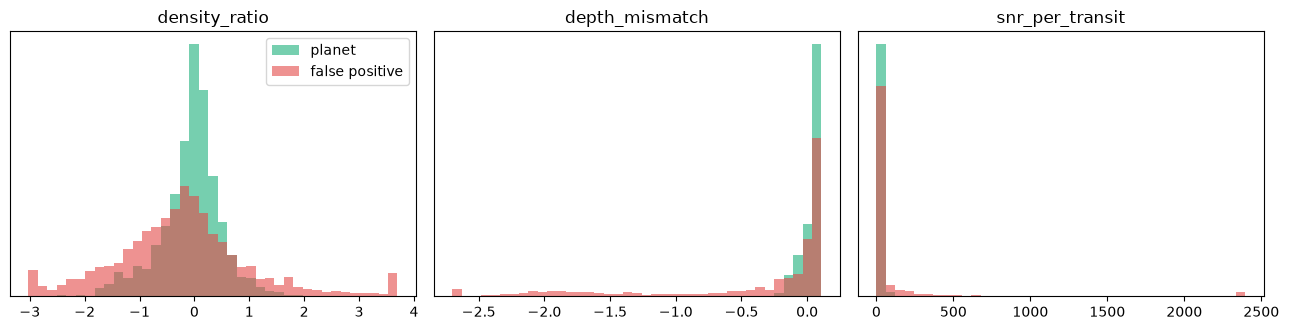

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, ["density_ratio", "depth_mismatch", "snr_per_transit"]):
    v = X_train[c]
    lo, hi = v.quantile(0.01), v.quantile(0.99)
    bins = np.linspace(lo, hi, 40)
    ax.hist(v[y_train == 1].clip(lo, hi).dropna(), bins=bins, alpha=0.6, density=True, label="planet", color="#1baf7a")
    ax.hist(v[y_train == 0].clip(lo, hi).dropna(), bins=bins, alpha=0.6, density=True, label="false positive", color="#e34948")
    ax.set_title(c); ax.set_yticks([])
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG / "B1_engineered_features.png", dpi=200); plt.show()

## Step 2 (M2): leakage experiment
Same Random Forest, same 5 grouped folds, three feature sets:
* **(a) physical only**: the 15 physical columns
* **(b) our final set**: + 3 automatic diagnostics + 3 engineered features (`FEATURES`)
* **(c) + leaky columns**: + `koi_score` and the four `koi_fpflag_*` flags

(c) is expected to be almost perfect, **not** because the model is better but because those columns were produced
by the vetting that decided the label: they contain the answer. A new detection would not have them.

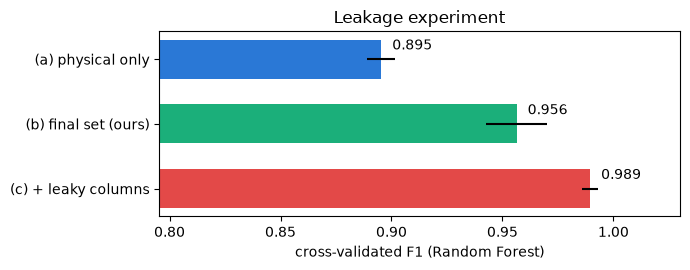

,features,CV F1 mean,CV F1 std
(a) physical only,15.0,0.8954,0.0062
(b) final set (ours),21.0,0.9564,0.0138
(c) + leaky columns,26.0,0.9895,0.0036


In [83]:
rf_fixed = make_tree_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                     random_state=RANDOM_STATE, n_jobs=-1))
feature_sets = {"(a) physical only": PHYSICAL,
                "(b) final set (ours)": FEATURES,
                "(c) + leaky columns": FEATURES + LEAKY_NUMERIC}
leak = {}
for name, cols in feature_sets.items():
    f1s = cross_val_score(rf_fixed, get_X(train, cols), y_train, groups=g_train, cv=cv, scoring="f1")
    leak[name] = {"features": len(cols), "CV F1 mean": f1s.mean(), "CV F1 std": f1s.std()}
leak = pd.DataFrame(leak).T
leak.to_csv(RES / "B2_leakage_experiment.csv")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(leak.index[::-1], leak["CV F1 mean"][::-1], xerr=leak["CV F1 std"][::-1],
        color=["#e34948", "#1baf7a", "#2a78d6"], height=0.6)
for i, v in enumerate(leak["CV F1 mean"][::-1]):
    ax.text(v + 0.005, i + 0.15, f"{v:.3f}")
ax.set_xlim(max(0, leak["CV F1 mean"].min() - 0.1), 1.03); ax.set_xlabel("cross-validated F1 (Random Forest)")
ax.set_title("Leakage experiment")
plt.tight_layout(); plt.savefig(FIG / "B2_leakage.png", dpi=200); plt.show()
leak.round(4)

## Step 3 (M3): lazy baseline and logistic regression
**Baseline** (Recitation 3.1): always predicts the majority class (false positive). Its F1 is 0: every model must beat it.

**Logistic regression** (scaled pipeline): `C = 1/λ` controls regularisation (small C = simpler model);
L1 can set weights exactly to zero (feature selection), L2 shrinks all weights; `class_weight="balanced"` gives the
rarer class (planets) more weight.

In [84]:
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results["Baseline"] = {"model": base, "cv_f1": 0.0, "cv_std": 0.0, "train_f1": 0.0, "seconds": 0.0, "params": "-"}
print("Baseline on validation:", {k: round(v, 3) for k, v in scores(y_val, base.predict_proba(X_val)[:, 1]).items()})

Baseline on validation: {'F1': 0.0, 'precision': 0.0, 'recall': 0.0, 'accuracy': 0.624}


In [85]:
def tune(name, pipeline, grid, random=False, n_iter=20):
    Search = RandomizedSearchCV if random else GridSearchCV
    extra = {"n_iter": n_iter, "random_state": RANDOM_STATE} if random else {}
    search = Search(pipeline, grid, cv=cv, scoring="f1", return_train_score=True, n_jobs=-1, **extra)
    t0 = time.time()
    search.fit(X_train, y_train, groups=g_train)
    seconds = time.time() - t0
    i = search.best_index_
    results[name] = {"model": search.best_estimator_, "search": search, "seconds": seconds,
                     "cv_f1": search.cv_results_["mean_test_score"][i], "cv_std": search.cv_results_["std_test_score"][i],
                     "train_f1": search.cv_results_["mean_train_score"][i], "params": search.best_params_}
    print(f"{name}: CV F1 {results[name]['cv_f1']:.4f} ± {results[name]['cv_std']:.4f} | train F1 "
          f"{results[name]['train_f1']:.4f} | {seconds:.0f}s | best {search.best_params_}")
    return search

# scikit-learn >= 1.8 chooses L1/L2 with l1_ratio (0 = L2, 1 = L1); older versions use penalty
NEW_SK = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)
PEN = {"model__l1_ratio": [0.0, 1.0]} if NEW_SK else {"model__penalty": ["l2", "l1"]}
PEN_KEY = list(PEN)[0]

lr_search = tune("LogReg",
                 make_scaled_pipeline(LogisticRegression(solver="liblinear", max_iter=5000)),
                 {"model__C": [0.001, 0.01, 0.1, 1, 10, 100], **PEN, "model__class_weight": [None, "balanced"]})

LogReg: CV F1 0.9406 ± 0.0114 | train F1 0.9439 | 16s | best {'model__C': 10, 'model__class_weight': None, 'model__l1_ratio': 0.0}


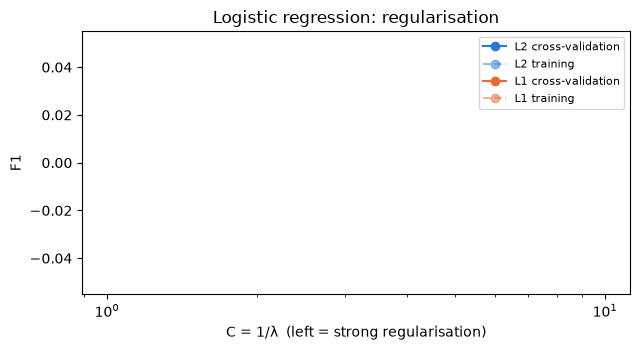

non-zero weights: 40 of 40


In [86]:
r = pd.DataFrame(lr_search.cv_results_)
best_cw = str(lr_search.best_params_["model__class_weight"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for pen, label, color in [(PEN[PEN_KEY][0], "L2", "#2a78d6"), (PEN[PEN_KEY][1], "L1", "#eb6834")]:
    s = r[(r[f"param_{PEN_KEY}"] == pen) & (r["param_model__class_weight"].astype(str) == best_cw)].sort_values("param_model__C")
    ax.plot(s["param_model__C"].astype(float), s["mean_test_score"], "o-", color=color, label=f"{label} cross-validation")
    ax.plot(s["param_model__C"].astype(float), s["mean_train_score"], "o--", color=color, alpha=0.5, label=f"{label} training")
ax.set_xscale("log"); ax.set_xlabel("C = 1/λ  (left = strong regularisation)"); ax.set_ylabel("F1")
ax.set_title("Logistic regression: regularisation"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "B3_logreg_C.png", dpi=200); plt.show()
w = results["LogReg"]["model"].named_steps["model"].coef_.ravel()
print(f"non-zero weights: {(w != 0).sum()} of {w.size}")

## Step 4 (M4): decision tree
The tree asks yes/no questions chosen by Gini impurity (Recitation 6). Unlimited depth memorises the training data;
`max_depth` and `min_samples_leaf` control that.

DecisionTree: CV F1 0.9249 ± 0.0096 | train F1 0.9627 | 3s | best {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 1}


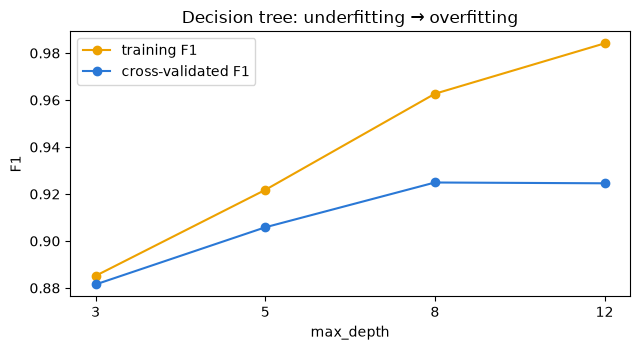

In [87]:
dt_search = tune("DecisionTree",
                 make_tree_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                 {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_leaf": [1, 10, 50],
                  "model__class_weight": [None, "balanced"]})

r = pd.DataFrame(dt_search.cv_results_)
bp = dt_search.best_params_
s = r[(r["param_model__min_samples_leaf"] == bp["model__min_samples_leaf"]) &
      (r["param_model__class_weight"].astype(str) == str(bp["model__class_weight"]))].copy()
s["depth"] = s["param_model__max_depth"].astype(str)
s = s.set_index("depth").loc[[d for d in ["3", "5", "8", "12", "None"] if d in set(s["depth"])]]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(s.index, s["mean_train_score"], "o-", color="#eda100", label="training F1")
ax.plot(s.index, s["mean_test_score"], "o-", color="#2a78d6", label="cross-validated F1")
ax.set_xlabel("max_depth"); ax.set_ylabel("F1"); ax.set_title("Decision tree: underfitting → overfitting"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "B4_tree_depth.png", dpi=200); plt.show()

## Step 5 (M5): Random Forest and AdaBoost
**Random Forest** (Recitation 6): many trees, each on a bootstrap sample of rows and a random subset of features
per split; their vote reduces the variance of a single tree.
**AdaBoost** (Recitation 6): small trees added one after another, each focusing on the KOIs the previous ones got wrong.
Large search spaces → `RandomizedSearchCV` with a fixed budget of 20 settings (Recitation 4).

In [88]:
rf_search = tune("RandomForest",
                 make_tree_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
                 {"model__n_estimators": [200, 400], "model__max_depth": [None, 10, 20],
                  "model__min_samples_leaf": [1, 3, 5], "model__max_features": ["sqrt", 0.3, 0.5],
                  "model__class_weight": [None, "balanced"]},
                 random=True, n_iter=20)

RandomForest: CV F1 0.9548 ± 0.0104 | train F1 1.0000 | 99s | best {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': None}


In [89]:
ada_search = tune("AdaBoost",
                  make_tree_pipeline(AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                        random_state=RANDOM_STATE)),
                  {"model__estimator__max_depth": [1, 2, 3], "model__n_estimators": [100, 200, 400],
                   "model__learning_rate": [0.1, 0.5, 1.0]},
                  random=True, n_iter=20)

AdaBoost: CV F1 0.9608 ± 0.0080 | train F1 1.0000 | 89s | best {'model__n_estimators': 100, 'model__learning_rate': 1.0, 'model__estimator__max_depth': 3}


## Step 6 (M6): summary, validation scores, save everything
* **CV F1** = mean over the 5 grouped folds of the training set; **train F1 − CV F1** = overfitting gap.
* **Validation F1** at threshold 0.5 (thresholds are tuned later, in M7, on the validation set).
* Each model's validation **and** test probabilities are saved to `results/preds_<Model>.csv` for M7.
  We do **not** look at test scores here.

In [90]:
rows = []
for name, r in results.items():
    p_val = r["model"].predict_proba(X_val)[:, 1]
    v = scores(y_val, p_val)
    rows.append({"model": name, "level": "baseline" if name == "Baseline" else "Level 1",
                 "CV F1": r["cv_f1"], "CV std": r["cv_std"], "train F1": r["train_f1"],
                 "overfit gap": r["train_f1"] - r["cv_f1"], "val F1": v["F1"], "val precision": v["precision"],
                 "val recall": v["recall"], "tuning s": r["seconds"], "best params": str(r["params"])})
summary = pd.DataFrame(rows).set_index("model")
summary.to_csv(RES / "B6_level1_summary.csv")
summary.drop(columns="best params").round(4)

,level,CV F1,CV std,train F1,overfit gap,val F1,val precision,val recall,tuning s
model,,,,,,,,,
Baseline,baseline,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
LogReg,Level 1,0.9406,0.0114,0.9439,0.0033,0.9317,0.9214,0.9423,16.2795
DecisionTree,Level 1,0.9249,0.0096,0.9627,0.0378,0.9131,0.8904,0.9371,2.8087
RandomForest,Level 1,0.9548,0.0104,1.0000,0.0452,0.9512,0.9658,0.9371,99.2323
AdaBoost,Level 1,0.9608,0.0080,1.0000,0.0392,0.9496,0.9446,0.9545,89.2874


In [91]:
for name, r in results.items():
    joblib.dump(r["model"], MODELS / f"{name}.joblib", compress=3)
    parts = []
    for part, X_, y_ in [("val", X_val, y_val), ("test", X_test, y_test)]:
        frame = (val if part == "val" else test)[["kepoi_name", "kepid"]].copy()
        frame["label"], frame["split"], frame["p"] = y_, part, r["model"].predict_proba(X_)[:, 1]
        parts.append(frame)
    pd.concat(parts).to_csv(RES / f"preds_{name}.csv", index=False)
print("saved:", sorted(p.name for p in MODELS.glob("*.joblib")), "and preds_<Model>.csv in results/")

saved: ['AdaBoost.joblib', 'Baseline.joblib', 'DecisionTree.joblib', 'LogReg.joblib', 'RandomForest.joblib', 'final_model.joblib', 'neural_net_preprocess.joblib'] and preds_<Model>.csv in results/


### What to write in the report (from this notebook)
* Leakage experiment (figure B2): F1 with leaky columns vs our final set, and why the leaky columns are excluded.
* Engineered features (figure B1): `density_ratio` separates planets from false positives.
* For each Level 1 model: why it was chosen, the search grid, the best parameters, CV F1 ± std and the overfitting
  gap (table B6, figures B3–B4).

---
# P4 · Level 2: neural network
*Owner: Hend · source notebook: `notebooks/P4_neural_network.ipynb`*

# P4 · Level 2: neural network (PyTorch, as in Recitation 7)
**Owner: Member A** · CMPS 261 Project 4.1 · Kepler Objects of Interest

Plan:
1. Inputs: the **scaled** pipeline (median imputation + "was missing" columns → StandardScaler), fitted on **train rows only**.
2. Network: `Linear → ReLU → (Dropout)` per hidden layer, then `Linear → Sigmoid`. `BCELoss`, AdamW (lr 1e-3), batch 64, up to 300 epochs, **early stopping** on validation loss (patience 20), best weights restored.
3. Compare 5 settings and choose the one with the **lowest validation loss** (R7).
4. Plot training vs validation loss (chosen setting vs (128, 64) without regularisation).
5. Run the chosen setting with 3 seeds (randomness of initialisation).
6. Save `models/neural_net.pt` and `results/preds_NeuralNet.csv`.

F1 here uses threshold 0.5. The threshold itself is tuned on validation in P5. The test set is only predicted and saved, never looked at.

## 0. Setup

In [92]:
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/kepler-koi-classification/notebooks")

import json, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, precision_score, recall_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # so `import features` finds features.py in the repo root
(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "results").mkdir(exist_ok=True)

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Repo root:", ROOT, "| device:", DEVICE)

Repo root: c:\Users\Administrator\kepler-koi-classification | device: cpu


## 1. Data and features
`koi_split.csv` comes from P1. The feature list, the engineered features and the scaled pipeline come from **B's `features.py`** (P2), so the network gets exactly the same inputs as the classical models. `get_X()` adds the 3 engineered features and the log columns and returns the 21 features in a fixed order.

In [93]:
from features import FEATURES, get_X, make_scaled_pipeline

df = pd.read_csv(ROOT / "data" / "processed" / "koi_split.csv", low_memory=False)
print(df["split"].value_counts().to_dict())

is_tr, is_va, is_te = (df["split"] == s for s in ["train", "val", "test"])

prep = make_scaled_pipeline()                      # imputer(median, indicator) -> StandardScaler
X_tr = prep.fit_transform(get_X(df[is_tr]))        # statistics learned on train rows only
X_va = prep.transform(get_X(df[is_va]))
X_te = prep.transform(get_X(df[is_te]))
y_tr, y_va, y_te = (df.loc[m, "label"].to_numpy() for m in [is_tr, is_va, is_te])
print(f"Inputs: {X_tr.shape[1]} columns ({len(FEATURES)} features + 'was missing' indicators)")
print("train / val / test rows:", len(y_tr), len(y_va), len(y_te))

{'train': 4519, 'test': 1546, 'val': 1522}
Inputs: 40 columns (21 features + 'was missing' indicators)
train / val / test rows: 4519 1522 1546


In [94]:
def to_tensor(X, y=None):
    X = torch.tensor(X, dtype=torch.float32)
    if y is None:
        return X
    return X, torch.tensor(y, dtype=torch.float32).view(-1, 1)   # labels float, shape [n, 1]

Xtr_t, ytr_t = to_tensor(X_tr, y_tr)
Xva_t, yva_t = to_tensor(X_va, y_va)
Xte_t = to_tensor(X_te)

## 2. Network and training loop

In [95]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden, dropout=0.0):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers += [nn.Linear(prev, 1), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return model(X.to(DEVICE)).cpu().numpy().ravel()


def train_mlp(hidden, dropout=0.0, weight_decay=0.0, seed=SEED,
              lr=1e-3, batch_size=64, max_epochs=300, patience=20):
    torch.manual_seed(seed); np.random.seed(seed)
    model = MLP(X_tr.shape[1], hidden, dropout).to(DEVICE)
    # AdamW's default weight_decay is 0.01, so set it explicitly (0 = no weight decay)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCELoss()
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"train_loss": [], "val_loss": []}
    best_val, best_state, best_epoch, wait = np.inf, None, 0, 0
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            tr_loss = loss_fn(model(Xtr_t.to(DEVICE)), ytr_t.to(DEVICE)).item()
            va_loss = loss_fn(model(Xva_t.to(DEVICE)), yva_t.to(DEVICE)).item()
        hist["train_loss"].append(tr_loss); hist["val_loss"].append(va_loss)

        if va_loss < best_val:                       # early stopping on validation loss
            best_val, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)                # restore the best weights
    train_time = time.time() - t0

    p_tr, p_va = predict_proba(model, Xtr_t), predict_proba(model, Xva_t)
    result = {
        "params":     sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch,
        "epochs_run": len(hist["val_loss"]),
        "train_F1":   f1_score(y_tr, p_tr >= 0.5),
        "val_loss":   best_val,
        "val_F1":     f1_score(y_va, p_va >= 0.5),
        "train_time_s": train_time,
    }
    return model, hist, result

## 3. Compare 5 settings (choose the lowest validation loss)

In [96]:
SETTINGS = {
    "(32)":                       dict(hidden=(32,)),
    "(64, 32)":                   dict(hidden=(64, 32)),
    "(128, 64)":                  dict(hidden=(128, 64)),
    "(128, 64) + dropout":        dict(hidden=(128, 64), dropout=0.3),
    "(128, 64) + dropout + wd":   dict(hidden=(128, 64), dropout=0.3, weight_decay=0.01),
}

runs, rows = {}, []
for name, cfg in SETTINGS.items():
    model, hist, res = train_mlp(**cfg)
    runs[name] = (model, hist, cfg)
    rows.append({"setting": name, **res})
    print(f"{name:<26} best epoch {res['best_epoch']:>3}   val loss {res['val_loss']:.4f}   val F1 {res['val_F1']:.3f}")

table = pd.DataFrame(rows).set_index("setting")
table["train_F1"] = table["train_F1"].round(3); table["val_F1"] = table["val_F1"].round(3)
table["val_loss"] = table["val_loss"].round(4); table["train_time_s"] = table["train_time_s"].round(1)
CHOSEN = table["val_loss"].idxmin()
print("\nChosen setting (lowest validation loss):", CHOSEN)
table

(32)                       best epoch  49   val loss 0.1158   val F1 0.949
(64, 32)                   best epoch  19   val loss 0.1158   val F1 0.945
(128, 64)                  best epoch  13   val loss 0.1113   val F1 0.950
(128, 64) + dropout        best epoch  20   val loss 0.1150   val F1 0.945
(128, 64) + dropout + wd   best epoch  20   val loss 0.1145   val F1 0.946

Chosen setting (lowest validation loss): (128, 64)


,params,best_epoch,epochs_run,train_F1,val_loss,val_F1,train_time_s
setting,,,,,,,
(32),1345,49,69,0.968,0.1158,0.949,7.9
"(64, 32)",4737,19,39,0.970,0.1158,0.945,6.1
"(128, 64)",13569,13,33,0.970,0.1113,0.950,4.5
"(128, 64) + dropout",13569,20,40,0.971,0.1150,0.945,5.7
"(128, 64) + dropout + wd",13569,20,40,0.972,0.1145,0.946,5.7


## 4. Training vs validation loss
Left: the chosen setting. Right: (128, 64) without regularisation (or, if that is the chosen one, the version with dropout + weight decay). If the validation loss turns upward while the training loss keeps falling, the network has started memorising the training data (overfitting). The dotted line marks the epoch whose weights were kept.

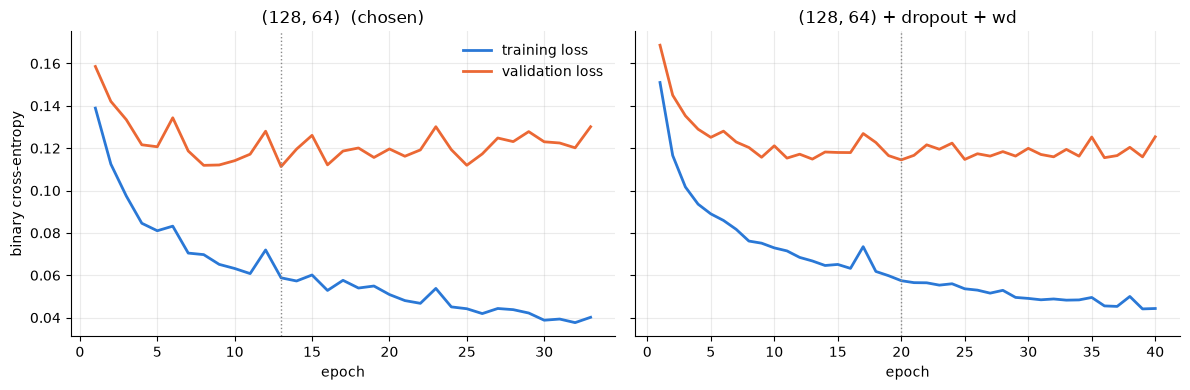

In [97]:
TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"
# chosen setting vs (128, 64) without regularisation; if those are the same, compare with the regularised one
panels = [CHOSEN, "(128, 64)"] if CHOSEN != "(128, 64)" else ["(128, 64)", "(128, 64) + dropout + wd"]
fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 4), sharey=True, squeeze=False)
for ax, name in zip(axes[0], panels):
    hist = runs[name][1]
    epochs = range(1, len(hist["train_loss"]) + 1)
    ax.plot(epochs, hist["train_loss"], color=TRAIN_COLOR, lw=2, label="training loss")
    ax.plot(epochs, hist["val_loss"],   color=VAL_COLOR,   lw=2, label="validation loss")
    best = int(np.argmin(hist["val_loss"])) + 1
    ax.axvline(best, color="#888888", lw=1, ls=":")
    ax.set_title(f"{name}{'  (chosen)' if name == CHOSEN else ''}")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.25)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0][0].set_ylabel("binary cross-entropy")
axes[0][0].legend(frameon=False)
plt.tight_layout()
plt.savefig(ROOT / "results" / "nn_loss_curves.png", dpi=150)
plt.show()

## 5. Randomness of initialisation (3 seeds)

In [98]:
seed_rows = []
for s in [0, 1, 2]:
    _, _, res = train_mlp(**SETTINGS[CHOSEN], seed=s)
    seed_rows.append({"seed": s, "best_epoch": res["best_epoch"],
                      "val_loss": round(res["val_loss"], 4), "val_F1": round(res["val_F1"], 3)})
seeds = pd.DataFrame(seed_rows).set_index("seed")
print(f"Validation F1 over 3 seeds: {seeds['val_F1'].mean():.3f} ± {seeds['val_F1'].std():.3f}")
seeds

Validation F1 over 3 seeds: 0.947 ± 0.003


,best_epoch,val_loss,val_F1
seed,,,
0,13,0.1141,0.948
1,12,0.1123,0.943
2,19,0.1123,0.949


## 6. Save the model and the predictions
The model trained with `SEED = 42` is the one kept. `preds_NeuralNet.csv` has `kepoi_name, label, split, p` for validation and test rows (shared format from the plan); P5 chooses the threshold on the validation rows and evaluates once on test.

In [99]:
final_model, _, final_cfg = runs[CHOSEN]
torch.save(final_model.state_dict(), ROOT / "models" / "neural_net.pt")
joblib.dump(prep, ROOT / "models" / "neural_net_preprocess.joblib")      # the fitted scaled pipeline
(ROOT / "models" / "neural_net_config.json").write_text(json.dumps({
    "setting": CHOSEN, "n_inputs": X_tr.shape[1], "hidden": list(final_cfg["hidden"]),
    "dropout": final_cfg.get("dropout", 0.0), "weight_decay": final_cfg.get("weight_decay", 0.0),
    "features": FEATURES, "seed": SEED}, indent=2))

preds = pd.concat([
    df.loc[is_va, ["kepoi_name", "label", "split"]].assign(p=predict_proba(final_model, Xva_t)),
    df.loc[is_te, ["kepoi_name", "label", "split"]].assign(p=predict_proba(final_model, Xte_t)),
])
preds.to_csv(ROOT / "results" / "preds_NeuralNet.csv", index=False)
print("Saved models/neural_net.pt, models/neural_net_preprocess.joblib, models/neural_net_config.json")
print(f"Saved results/preds_NeuralNet.csv ({len(preds)} rows: val + test)")
table.to_csv(ROOT / "results" / "nn_settings.csv")
print("Next: commit and push → message 'P4: neural network'")

Saved models/neural_net.pt, models/neural_net_preprocess.joblib, models/neural_net_config.json
Saved results/preds_NeuralNet.csv (3068 rows: val + test)
Next: commit and push → message 'P4: neural network'


## Explain (for the report / professor)
*"Early stopping stops when the validation loss stops improving, before the network memorises the training data; dropout and weight decay are regularisation."*

To load the saved model later (P5 / P7):
```python
cfg = json.loads((ROOT / "models" / "neural_net_config.json").read_text())
model = MLP(cfg["n_inputs"], cfg["hidden"], cfg["dropout"])
model.load_state_dict(torch.load(ROOT / "models" / "neural_net.pt"))
prep = joblib.load(ROOT / "models" / "neural_net_preprocess.joblib")
```

---
# P5 · Model comparison, one-time test and split sensitivity
*Owner: Mohamad · source notebook: `notebooks/B_comparison_test.ipynb`*

# Part B (Mohamad): model comparison, one-time test, split sensitivity
**Kepler KOI exoplanet classification · CMPS 261 project 4.1**

| Step | What happens | Course |
|---|---|---|
| 0 | Load every model's validation and test probabilities | |
| 1 | Choose each model's decision threshold on the **validation** set | R3.2: the threshold is a choice |
| 2 | Development comparison and the selection rule (written **before** testing) → final model | R6 §11 |
| 3 | Evaluate every frozen model **once** on the test set | R4: test once |
| 4 | Level 2 vs Level 1: what does the neural network improve? | Project brief |
| 5 | Threshold table for the final model | R3.2 |
| 6 | Split sensitivity: star vs random folds, and 3 new train/val/test splits | R4 §4 |

## Step 0: load the predictions

In [100]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from sklearn.model_selection import GroupKFold, KFold, GroupShuffleSplit, cross_val_score
warnings.filterwarnings("ignore")

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from features import get_X, make_scaled_pipeline, RANDOM_STATE

RES, FIG, MODELS = ROOT / "results", ROOT / "results" / "figures", ROOT / "models"
FIG.mkdir(parents=True, exist_ok=True)

NAMES = ["Baseline", "LogReg", "DecisionTree", "RandomForest", "AdaBoost", "NeuralNet"]
LEVEL = {"Baseline": "baseline", "NeuralNet": "Level 2"}
COLORS = {"Baseline": "#9c9a92", "LogReg": "#2a78d6", "DecisionTree": "#eda100", "RandomForest": "#eb6834",
          "AdaBoost": "#1baf7a", "NeuralNet": "#6250d6"}

preds = None
for name in NAMES:
    p = pd.read_csv(RES / f"preds_{name}.csv")[["kepoi_name", "split", "label", "p"]].rename(columns={"p": name})
    preds = p if preds is None else preds.merge(p.drop(columns="label"), on=["kepoi_name", "split"], how="inner")
val, test = preds[preds.split == "val"].reset_index(drop=True), preds[preds.split == "test"].reset_index(drop=True)
print(f"validation KOIs: {len(val)} | test KOIs: {len(test)} | models: {NAMES}")

validation KOIs: 1522 | test KOIs: 1546 | models: ['Baseline', 'LogReg', 'DecisionTree', 'RandomForest', 'AdaBoost', 'NeuralNet']


In [101]:
def scores(y, p, thr):
    pred = (np.asarray(p) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"F1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "accuracy": accuracy_score(y, pred),
            "FPR": fp / (fp + tn), "TP": tp, "FP": fp, "FN": fn, "TN": tn}

## Step 1: decision thresholds, chosen on the validation set
The default threshold 0.5 is not always best (Recitation 3.2). For each model we try thresholds 0.05 to 0.95 on
the **validation** set and keep the one with the highest F1. The same rule is applied to every model, and the test
set is not used.

In [102]:
GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)
THR = {}
for name in NAMES:
    if name == "Baseline":
        THR[name] = 0.5           # the baseline always predicts "false positive": no threshold to tune
        continue
    f1s = [f1_score(val.label, val[name] >= t, zero_division=0) for t in GRID]
    THR[name] = float(GRID[int(np.argmax(f1s))])

dev = pd.DataFrame({name: {"level": LEVEL.get(name, "Level 1"), "threshold": THR[name],
                           "val F1 @0.5": scores(val.label, val[name], 0.5)["F1"],
                           **{f"val {k}": v for k, v in scores(val.label, val[name], THR[name]).items()
                              if k in ("F1", "precision", "recall", "accuracy")}}
                    for name in NAMES}).T
dev

,level,threshold,val F1 @0.5,val F1,val precision,val recall,val accuracy
Baseline,baseline,0.5,0.0,0.0,0.0,0.0,0.624179
LogReg,Level 1,0.58,0.93172,0.933566,0.933566,0.933566,0.950066
DecisionTree,Level 1,0.9,0.913118,0.915725,0.91019,0.921329,0.936268
RandomForest,Level 1,0.39,0.951198,0.953043,0.948097,0.958042,0.96452
AdaBoost,Level 1,0.5,0.949565,0.949565,0.944637,0.954545,0.961892
NeuralNet,Level 2,0.68,0.950478,0.953139,0.964222,0.942308,0.965177


## Step 2: development comparison and the selection rule
Recitation 6: *the highest validation score is not automatically the best practical choice*, so we also weigh
simplicity and interpretability. **Rule, written before looking at the test set:** take the model with the highest
validation F1; if a **simpler** model is within **0.01** of it, take the simpler one (the difference is within the
noise; Hend's seed check shows the network alone varies by about ±0.003).

Simplicity order: logistic regression < decision tree < Random Forest = AdaBoost < neural network.

In [103]:
SIMPLICITY = {"LogReg": 0, "DecisionTree": 1, "RandomForest": 2, "AdaBoost": 2, "NeuralNet": 3}
INTERPRETABILITY = {"Baseline": "-", "LogReg": "high (weights)", "DecisionTree": "high (if shallow)",
                    "RandomForest": "medium-low", "AdaBoost": "medium-low", "NeuralNet": "low"}
dev["interpretability"] = pd.Series(INTERPRETABILITY)

candidates = [n for n in NAMES if n != "Baseline"]
best = max(candidates, key=lambda n: dev.loc[n, "val F1"])
close = [n for n in candidates if dev.loc[best, "val F1"] - dev.loc[n, "val F1"] <= 0.01]
FINAL = min(close, key=lambda n: (SIMPLICITY[n], -dev.loc[n, "val F1"]))
best_l1 = max([n for n in candidates if n != "NeuralNet"], key=lambda n: dev.loc[n, "val F1"])

print(f"highest validation F1: {best} ({dev.loc[best, 'val F1']:.4f})")
print(f"within 0.01 of it:    {close}")
print(f"==> FINAL MODEL: {FINAL} (threshold {THR[FINAL]:.2f})  |  best Level-1 model: {best_l1}")
json.dump({"final_model": FINAL, "threshold": THR[FINAL], "thresholds": THR, "best_level1": best_l1,
           "rule": "highest validation F1; a simpler model within 0.01 is preferred"},
          open(RES / "final_choice.json", "w"), indent=2)
dev.to_csv(RES / "B7_development_comparison.csv")
dev[["level", "threshold", "val F1", "val precision", "val recall", "interpretability"]].round(4)

highest validation F1: NeuralNet (0.9531)
within 0.01 of it:    ['RandomForest', 'AdaBoost', 'NeuralNet']
==> FINAL MODEL: RandomForest (threshold 0.39)  |  best Level-1 model: RandomForest


,level,threshold,val F1,val precision,val recall,interpretability
Baseline,baseline,0.5,0.0,0.0,0.0,-
LogReg,Level 1,0.58,0.933566,0.933566,0.933566,high (weights)
DecisionTree,Level 1,0.9,0.915725,0.91019,0.921329,high (if shallow)
RandomForest,Level 1,0.39,0.953043,0.948097,0.958042,medium-low
AdaBoost,Level 1,0.5,0.949565,0.944637,0.954545,medium-low
NeuralNet,Level 2,0.68,0.953139,0.964222,0.942308,low


## Step 3: the one-time test
Everything is now frozen: features, hyper-parameters, thresholds and the final model (saved in
`results/final_choice.json`). Every model is evaluated **once** on the test set (20 % of the stars, never used
before). Nothing is changed after this cell.

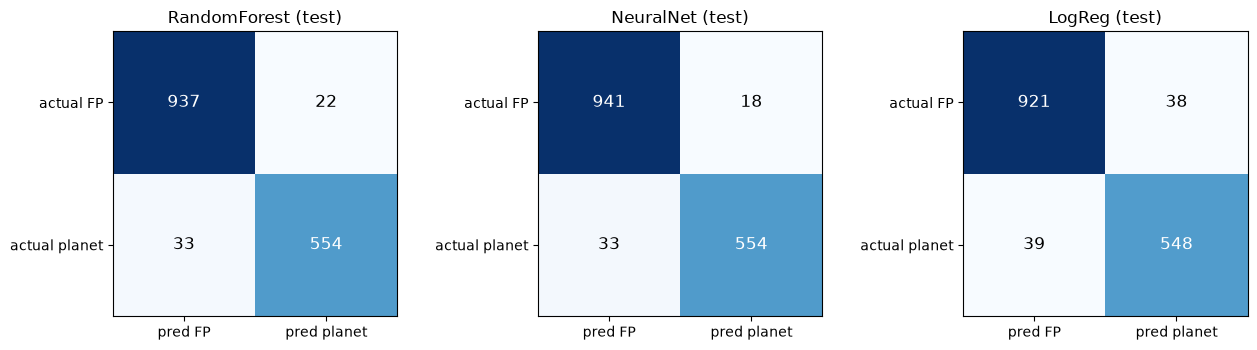

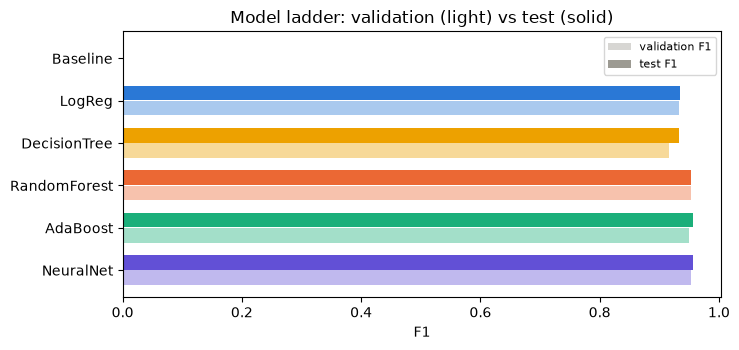

,level,threshold,F1,precision,recall,accuracy,FPR,val F1
Baseline,baseline,0.50,0.0000,0.0000,0.0000,0.6203,0.0000,0.0000
LogReg,Level 1,0.58,0.9344,0.9352,0.9336,0.9502,0.0396,0.9336
DecisionTree,Level 1,0.90,0.9330,0.9291,0.9370,0.9489,0.0438,0.9157
RandomForest,Level 1,0.39,0.9527,0.9618,0.9438,0.9644,0.0229,0.9530
AdaBoost,Level 1,0.50,0.9564,0.9605,0.9523,0.9670,0.0240,0.9496
NeuralNet,Level 2,0.68,0.9560,0.9685,0.9438,0.9670,0.0188,0.9531


In [104]:
test_table = pd.DataFrame({n: {"level": LEVEL.get(n, "Level 1"), "threshold": THR[n], **scores(test.label, test[n], THR[n])}
                           for n in NAMES}).T
test_table["val F1"] = dev["val F1"]
test_table.to_csv(RES / "B7_test_results.csv")
test[["kepoi_name", "label"] + NAMES].rename(columns={n: f"p_{n}" for n in NAMES}).to_csv(RES / "test_predictions.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, n in zip(axes, dict.fromkeys([FINAL, best_l1, "NeuralNet", "LogReg"]).__iter__()):
    cm = confusion_matrix(test.label, test[n] >= THR[n], labels=[0, 1])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=12, color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred FP", "pred planet"]); ax.set_yticks([0, 1], ["actual FP", "actual planet"])
    ax.set_title(f"{n} (test)")
plt.tight_layout(); plt.savefig(FIG / "B7_confusion_matrices.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
yy = np.arange(len(NAMES))
ax.barh(yy + 0.18, test_table["val F1"].astype(float), height=0.34, color=[COLORS[n] for n in NAMES], alpha=0.4, label="validation F1")
ax.barh(yy - 0.18, test_table["F1"].astype(float), height=0.34, color=[COLORS[n] for n in NAMES], label="test F1")
ax.set_yticks(yy, NAMES); ax.invert_yaxis(); ax.set_xlabel("F1"); ax.legend(fontsize=8)
ax.set_title("Model ladder: validation (light) vs test (solid)")
plt.tight_layout(); plt.savefig(FIG / "B7_model_ladder.png", dpi=200); plt.show()
test_table[["level", "threshold", "F1", "precision", "recall", "accuracy", "FPR", "val F1"]].astype(
    {c: float for c in ["threshold", "F1", "precision", "recall", "accuracy", "FPR", "val F1"]}).round(4)

## Step 4: what does the neural network (Level 2) improve over the best Level 1 model?

In [105]:
nn, l1 = test_table.loc["NeuralNet"], test_table.loc[best_l1]
print(f"Test F1   NeuralNet {nn['F1']:.4f}  vs  {best_l1} {l1['F1']:.4f}  ->  difference {nn['F1'] - l1['F1']:+.4f}")
print(f"Precision NeuralNet {nn['precision']:.4f}  vs  {l1['precision']:.4f}")
print(f"Recall    NeuralNet {nn['recall']:.4f}  vs  {l1['recall']:.4f}")
print("Compare this difference with the spread across seeds (Hend: about ±0.003) and across splits (step 6).")

Test F1   NeuralNet 0.9560  vs  RandomForest 0.9527  ->  difference +0.0033
Precision NeuralNet 0.9685  vs  0.9618
Recall    NeuralNet 0.9438  vs  0.9438
Compare this difference with the spread across seeds (Hend: about ±0.003) and across splits (step 6).


## Step 5: threshold table for the final model (validation set)
Lower threshold → more planets found (recall up) but more false positives accepted (precision down). A follow-up
programme with little telescope time wants high precision; a survey that must not miss planets wants high recall.

In [106]:
sweep = pd.DataFrame([{"threshold": t, **{k: v for k, v in scores(val.label, val[FINAL], t).items()
                                          if k in ("F1", "precision", "recall", "FP", "FN")}}
                      for t in [0.3, 0.4, 0.5, 0.6, 0.7]]).set_index("threshold")
sweep.to_csv(RES / "B7_threshold_table.csv")
sweep.round(4)

,F1,precision,recall,FP,FN
threshold,,,,,
0.3,0.9438,0.9203,0.9685,48,18
0.4,0.9530,0.9497,0.9563,29,25
0.5,0.9512,0.9658,0.9371,19,36
0.6,0.9372,0.9772,0.9003,12,57
0.7,0.9229,0.9842,0.8689,8,75


## Step 6: how sensitive are the conclusions to the split?
**(a) Star folds vs random-row folds** (Random Forest, best settings, training rows): if random folds score higher,
the difference is the optimism caused by letting KOIs of the same star sit on both sides.

**(b) Three new 60/20/20 star splits** (seeds 1, 2, 3): every model is retrained with its **frozen** settings and
threshold (no re-tuning) and scored on the new test set. Does the ranking of the models stay the same?

In [107]:
data = pd.read_csv(ROOT / "data" / "processed" / "koi_split.csv", low_memory=False)
tr = data[data.split == "train"]
rf = joblib.load(MODELS / "RandomForest.joblib")
f1_star = cross_val_score(clone(rf), get_X(tr), tr.label, groups=tr.kepid, cv=GroupKFold(5), scoring="f1", n_jobs=-1)
f1_rand = cross_val_score(clone(rf), get_X(tr), tr.label, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="f1", n_jobs=-1)
split_cmp = pd.DataFrame({"F1 mean": [f1_star.mean(), f1_rand.mean()], "F1 std": [f1_star.std(), f1_rand.std()]},
                         index=["folds by star (ours)", "random row folds"])
split_cmp.to_csv(RES / "B7_star_vs_random_folds.csv")
split_cmp.round(4)

,F1 mean,F1 std
folds by star (ours),0.9548,0.0104
random row folds,0.9556,0.0071


In [108]:
# Neural network retraining uses Hend's exact training procedure (P4). Needs PyTorch: pip install torch
try:
    import copy, torch, torch.nn as tnn
    from torch.utils.data import TensorDataset, DataLoader
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("PyTorch not installed: the neural network is skipped in step 6(b). Install it with `pip install torch` to include it.")

def train_nn(Xtr, ytr, Xva, yva, cfg, seed=42, lr=1e-3, batch_size=64, max_epochs=300, patience=20):
    torch.manual_seed(seed); np.random.seed(seed)
    layers, prev = [], Xtr.shape[1]
    for h in cfg["hidden"]:
        layers += [tnn.Linear(prev, h), tnn.ReLU()]
        if cfg.get("dropout", 0) > 0:
            layers.append(tnn.Dropout(cfg["dropout"]))
        prev = h
    model = tnn.Sequential(*layers, tnn.Linear(prev, 1), tnn.Sigmoid())
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=cfg.get("weight_decay", 0.0))
    loss_fn = tnn.BCELoss()
    Xt, yt = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xv, yv = torch.tensor(Xva, dtype=torch.float32), torch.tensor(yva, dtype=torch.float32).view(-1, 1)
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(seed))
    best, best_state, wait = np.inf, None, 0
    for epoch in range(max_epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); loss_fn(model(xb), yb).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = loss_fn(model(Xv), yv).item()
        if v < best:
            best, best_state, wait = v, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    return lambda X: model(torch.tensor(X, dtype=torch.float32)).detach().numpy().ravel()

seed 1 done
seed 2 done
seed 3 done


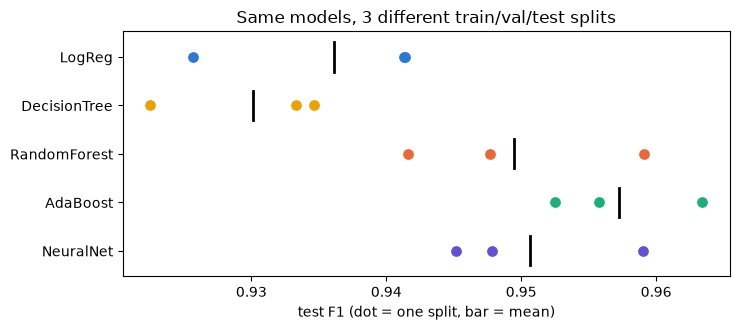

rank of each model per split (1 = best):


model,LogReg,DecisionTree,RandomForest,AdaBoost,NeuralNet
seed,,,,,
1,4.0,5.0,2.0,1.0,3.0
2,4.0,5.0,3.0,1.0,2.0
3,4.0,5.0,3.0,1.0,2.0


,mean,std,min,max
model,,,,
LogReg,0.9361,0.0090,0.9257,0.9414
DecisionTree,0.9302,0.0067,0.9225,0.9346
RandomForest,0.9494,0.0089,0.9416,0.9591
AdaBoost,0.9572,0.0056,0.9525,0.9634
NeuralNet,0.9507,0.0074,0.9451,0.9591


In [109]:
nn_cfg = json.load(open(MODELS / "neural_net_config.json"))
sk_models = {n: joblib.load(MODELS / f"{n}.joblib") for n in ["LogReg", "DecisionTree", "RandomForest", "AdaBoost"]}
rows = []
for seed in [1, 2, 3]:
    rest_i, te_i = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(data, groups=data.kepid))
    rest, te = data.iloc[rest_i], data.iloc[te_i]
    tr_i, va_i = next(GroupShuffleSplit(1, test_size=0.25, random_state=seed).split(rest, groups=rest.kepid))
    trn, vln = rest.iloc[tr_i], rest.iloc[va_i]
    Xtr, Xva, Xte = get_X(trn), get_X(vln), get_X(te)
    for n, m in sk_models.items():
        p = clone(m).fit(Xtr, trn.label).predict_proba(Xte)[:, 1]
        rows.append({"seed": seed, "model": n, "test F1": f1_score(te.label, p >= THR[n])})
    if HAS_TORCH:
        prep = make_scaled_pipeline().fit(Xtr)
        predict = train_nn(prep.transform(Xtr), trn.label.values, prep.transform(Xva), vln.label.values, nn_cfg)
        rows.append({"seed": seed, "model": "NeuralNet", "test F1": f1_score(te.label, predict(prep.transform(Xte)) >= THR["NeuralNet"])})
    print(f"seed {seed} done")
rep = pd.DataFrame(rows)
rep.to_csv(RES / "B7_repeated_splits.csv", index=False)

order = [n for n in NAMES if n in set(rep.model)]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for i, n in enumerate(order):
    v = rep[rep.model == n]["test F1"].values
    ax.scatter(v, np.full(len(v), i), color=COLORS[n], s=45, zorder=3)
    ax.plot([v.mean()] * 2, [i - 0.3, i + 0.3], color="black", lw=2)
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.set_xlabel("test F1 (dot = one split, bar = mean)")
ax.set_title("Same models, 3 different train/val/test splits")
plt.tight_layout(); plt.savefig(FIG / "B7_split_sensitivity.png", dpi=200); plt.show()
print("rank of each model per split (1 = best):")
display(rep.pivot(index="seed", columns="model", values="test F1")[order].rank(axis=1, ascending=False))
rep.groupby("model")["test F1"].agg(["mean", "std", "min", "max"]).loc[order].round(4)

### What to write in the report (Results section)
* The validation comparison and the selection rule → which model is final, and why.
* The one-time test table and confusion matrices; the model ladder figure (best for the poster).
* Level 2 vs Level 1: the test F1 difference, compared with the seed and split variability.
* Threshold table: the precision/recall trade-off.
* Split sensitivity: star vs random folds, and whether the model ranking changes across splits.

**Next:** Hend's failure analysis uses `results/final_choice.json` and the final model's predictions.

---
# P6 · Failure analysis and trust in confidence
*Owner: Hend · source notebook: `notebooks/P6_failure_analysis.ipynb`*

# P6 · Failure analysis and trust in confidence
**Owner: Member A** · CMPS 261 Project 4.1 · Kepler Objects of Interest

The brief asks where the model makes mistakes (*weak signals, unusual stars, missing measurements, false positives that closely resemble real planets*) and whether its confidence can be trusted. Everything here uses the **final model's test predictions** at the threshold chosen on validation in P5. The test set is only *analysed*; no choice is made on it (thresholds for the mitigations are chosen on validation).

1. Error rate, missed planets and accepted false positives **by group**.
2. **False-positive types** (the `koi_fpflag_*` flags are used here only, never as model inputs).
3. **Hard cases**: the 10 false positives the model is most sure are planets.
4. **Confidence**: reliability plot and confident mistakes.
5. **Mitigations**: high-recall / high-precision thresholds, deferring uncertain cases to a human, recalibration.

## 0. Setup

In [110]:
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/kepler-koi-classification/notebooks")

import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, brier_score_loss)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from features import FEATURES, get_X

RESULTS = ROOT / "results"
FIGS = RESULTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#888888"
pd.set_option("display.max_columns", 30)
warnings.simplefilter("ignore", pd.errors.PerformanceWarning)
print("Repo root:", ROOT)

Repo root: c:\Users\Administrator\kepler-koi-classification


## 1. Final model and threshold
Read from `results/final_choice.json` (written by B in P5). **If P5 is not pushed yet**, a stand-in applies the plan's rule to the validation predictions: for each model, take the threshold that maximises validation F1; pick the highest validation F1, but if a simpler model is within 0.01, take the simpler one. Rerun this notebook once `final_choice.json` exists so P6 analyses exactly the model B selected.

In [111]:
MODELS = ["LogReg", "DecisionTree", "AdaBoost", "RandomForest", "NeuralNet"]   # simplest -> most complex
preds = {m: pd.read_csv(RESULTS / f"preds_{m}.csv") for m in MODELS if (RESULTS / f"preds_{m}.csv").exists()}

def best_threshold(y, p):
    grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
    f1s = [f1_score(y, p >= t, zero_division=0) for t in grid]
    i = int(np.argmax(f1s))
    return grid[i], f1s[i]

choice_file = RESULTS / "final_choice.json"
if choice_file.exists():
    choice = json.loads(choice_file.read_text())
    FINAL = choice.get("model") or choice.get("final_model") or choice.get("name")
    THRESHOLD = float(choice.get("threshold") or choice.get("final_threshold"))
    SOURCE = "final_choice.json (P5)"
else:
    rows = []
    for m, d in preds.items():
        v = d[d["split"] == "val"]
        t, f1 = best_threshold(v["label"], v["p"])
        rows.append({"model": m, "val_threshold": t, "val_F1": round(f1, 4)})
    val_table = pd.DataFrame(rows).set_index("model")
    best_f1 = val_table["val_F1"].max()
    FINAL = next(m for m in MODELS if m in val_table.index and val_table.loc[m, "val_F1"] >= best_f1 - 0.01)
    THRESHOLD = float(val_table.loc[FINAL, "val_threshold"])
    SOURCE = "stand-in rule (P5 not pushed yet)"
    display(val_table)

print(f"Final model: {FINAL}   threshold: {THRESHOLD}   source: {SOURCE}")

Final model: RandomForest   threshold: 0.39   source: final_choice.json (P5)


In [112]:
split = pd.read_csv(ROOT / "data" / "processed" / "koi_split.csv", low_memory=False)
p_all = preds[FINAL][["kepoi_name", "split", "p"]]
val  = split.merge(p_all[p_all["split"] == "val"][["kepoi_name", "p"]],  on="kepoi_name")
test = split.merge(p_all[p_all["split"] == "test"][["kepoi_name", "p"]], on="kepoi_name").copy()

test["pred"] = (test["p"] >= THRESHOLD).astype(int)
test["error"] = (test["pred"] != test["label"]).astype(int)
test["missed_planet"] = ((test["label"] == 1) & (test["pred"] == 0)).astype(int)    # false negative
test["accepted_fp"]   = ((test["label"] == 0) & (test["pred"] == 1)).astype(int)    # false positive
test["n_missing"] = get_X(test).isna().sum(axis=1)                                  # missing among the 21 model features

y, yhat = test["label"], test["pred"]
tn, fp, fn, tp = confusion_matrix(y, yhat).ravel()
print(f"Test rows: {len(test)}  |  F1 {f1_score(y, yhat):.3f}  precision {precision_score(y, yhat):.3f}  "
      f"recall {recall_score(y, yhat):.3f}  accuracy {accuracy_score(y, yhat):.3f}")
print(f"Confusion matrix: TN {tn}  FP {fp}  FN {fn}  TP {tp}   ->  {fn} missed planets, {fp} accepted false positives")

Test rows: 1546  |  F1 0.953  precision 0.962  recall 0.944  accuracy 0.964
Confusion matrix: TN 937  FP 22  FN 33  TP 554   ->  33 missed planets, 22 accepted false positives


## 2. Where does it fail? Error rate by group
For each group: **error rate** (all mistakes / rows), **miss rate** (missed planets / real planets) and **false-alarm rate** (accepted false positives / real false positives). Groups follow the plan; SNR, transits, star and planet values are the raw catalogue values (not log-transformed).

In [113]:
def bucket(s, bins, labels):
    out = pd.cut(s, bins=bins, labels=labels, right=False).astype(object)
    return out.where(s.notna(), "missing")

groupings = {
    "SNR":               bucket(test["koi_model_snr"], [-np.inf, 10, 50, np.inf], ["< 10", "10-50", "> 50"]),
    "transits observed": bucket(test["koi_num_transits"], [-np.inf, 4, np.inf], ["<= 3", "> 3"]),
    "missing values":    np.where(test["n_missing"] == 0, "0", ">= 1"),
    "star type":         np.where(test["koi_slogg"].isna(), "missing",
                                  np.where(test["koi_slogg"] < 3.5, "giant (logg < 3.5)", "dwarf (logg >= 3.5)")),
    "star temperature":  bucket(test["koi_steff"], [-np.inf, 5200, 6000, np.inf],
                                ["cool (< 5200 K)", "Sun-like (5200-6000 K)", "hot (> 6000 K)"]),
    "planet radius":     bucket(test["koi_prad"], [-np.inf, 15, np.inf], ["<= 15 Earth radii", "> 15 Earth radii"]),
}

rows = []
for gname, g in groupings.items():
    for level, d in test.groupby(np.asarray(g)):
        planets, fps = (d["label"] == 1).sum(), (d["label"] == 0).sum()
        rows.append({
            "group": gname, "level": level, "rows": len(d), "planet share": round(d["label"].mean(), 2),
            "error rate": round(d["error"].mean(), 3),
            "missed planets": int(d["missed_planet"].sum()),
            "miss rate": round(d["missed_planet"].sum() / planets, 3) if planets else np.nan,
            "accepted FPs": int(d["accepted_fp"].sum()),
            "false-alarm rate": round(d["accepted_fp"].sum() / fps, 3) if fps else np.nan,
        })
by_group = pd.DataFrame(rows).set_index(["group", "level"])
by_group.to_csv(RESULTS / "P6_errors_by_group.csv")
print(f"Overall test error rate: {test['error'].mean():.3f}")
by_group

Overall test error rate: 0.036


rows  planet share  error rate  \
group             level                                                    
SNR               10-50                    805          0.55       0.047   
                  < 10                     160          0.02       0.038   
                  > 50                     526          0.27       0.019   
                  missing                   55          0.00       0.018   
transits observed <= 3                      77          0.01       0.013   
                  > 3                     1323          0.44       0.039   
                  missing                  146          0.01       0.021   
missing values    0                       1324          0.44       0.039   
                  >= 1                     222          0.01       0.018   
star type         dwarf (logg >= 3.5)     1438          0.40       0.037   
                  giant (logg < 3.5)        53          0.09       0.019   
                  missing                   55          0.00       0.018   
star temperature  Sun-like (5200-6000 K)   659          0.44       0.030   
                  cool (< 5200 K)          297          0.53       0.057   
                  hot (> 6000 K)           535          0.25       0.032   
                  missing                   55          0.00       0.018   
planet radius     <= 15 Earth radii       1073          0.54       0.048   
                  > 15 Earth radii         418          0.01       0.007   
                  missing                   55          0.00       0.018   

                                          missed planets  miss rate  \
group             level                                               
SNR               10-50                               25      0.057   
                  < 10                                 3      0.750   
                  > 50                                 5      0.035   
                  missing                              0        NaN   
transits observed <= 3                                 1      1.000   
                  > 3                                 30      0.051   
                  missing                              2      1.000   
missing values    0                                   31      0.053   
                  >= 1                                 2      1.000   
star type         dwarf (logg >= 3.5)                 32      0.055   
                  giant (logg < 3.5)                   1      0.200   
                  missing                              0        NaN   
star temperature  Sun-like (5200-6000 K)              12      0.041   
                  cool (< 5200 K)                     13      0.082   
                  hot (> 6000 K)                       8      0.059   
                  missing                              0        NaN   
planet radius     <= 15 Earth radii                   30      0.051   
                  > 15 Earth radii                     3      0.750   
                  missing                              0        NaN   

                                          accepted FPs  false-alarm rate  
group             level                                                   
SNR               10-50                             13             0.036  
                  < 10                               3             0.019  
                  > 50                               5             0.013  
                  missing                            1             0.018  
transits observed <= 3                               0             0.000  
                  > 3                               21             0.028  
                  missing                            1             0.007  
missing values    0                                 20             0.027  
                  >= 1                               2             0.009  
star type         dwarf (logg >= 3.5)               21             0.025  
                  giant (logg < 3.5)                 

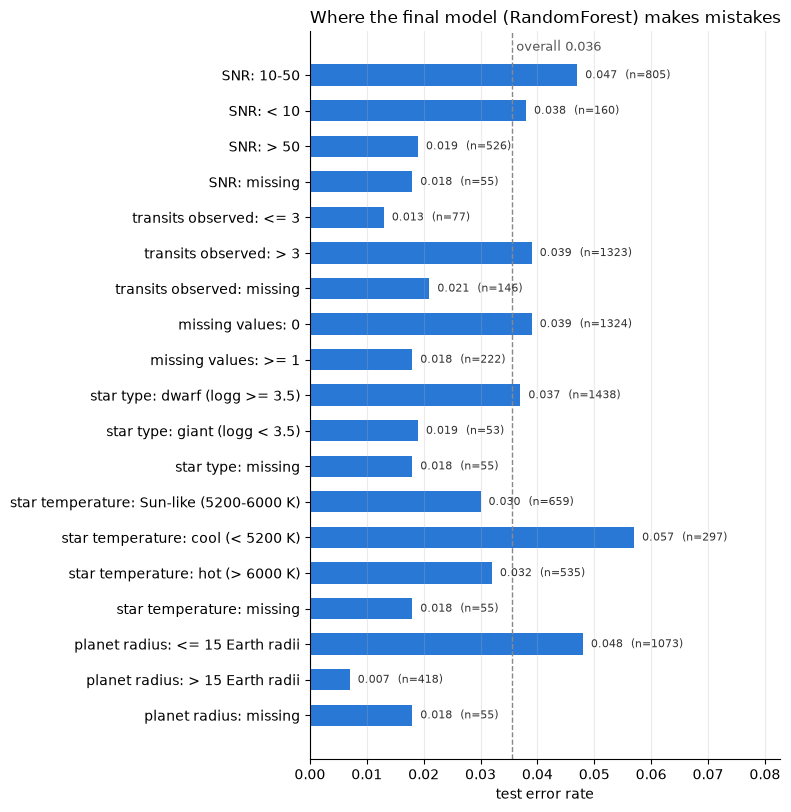

In [114]:
# Error rate per group (poster figure). Groups with < 20 test rows are flagged: their rates are noisy.
plot_df = by_group.reset_index()
plot_df["name"] = plot_df["group"] + ": " + plot_df["level"].astype(str)
plot_df = plot_df.iloc[::-1]
overall = test["error"].mean()

fig, ax = plt.subplots(figsize=(8, 0.38 * len(plot_df) + 1))
ax.barh(plot_df["name"], plot_df["error rate"], color=BLUE, height=0.6)
ax.axvline(overall, color=GRAY, lw=1, ls="--")
ax.text(overall, len(plot_df) - 0.4, f" overall {overall:.3f}", color="#555555", fontsize=9, va="bottom")
for i, (r, n) in enumerate(zip(plot_df["error rate"], plot_df["rows"])):
    ax.text(r, i, f"  {r:.3f}  (n={n}{', few rows' if n < 20 else ''})", va="center", fontsize=8, color="#333333")
ax.set_xlabel("test error rate")
ax.set_title(f"Where the final model ({FINAL}) makes mistakes", loc="left")
ax.set_xlim(0, max(plot_df["error rate"].max() * 1.45, overall * 2))
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGS / "P6_error_by_group.png", dpi=150)
plt.show()

## 3. Which kinds of false positive fool the model?
Among the **real false positives** in the test set: for each Kepler false-positive flag, how many carry it and how many the model wrongly called a planet. An object can carry several flags. (The flags are produced by vetting, so they are used **only here**, never as inputs.)

In [115]:
FLAGS = {"koi_fpflag_nt": "not transit-like", "koi_fpflag_ss": "stellar eclipse",
         "koi_fpflag_co": "centroid offset", "koi_fpflag_ec": "ephemeris match (contamination)"}
fp_test = test[test["label"] == 0]
rows = []
for col, meaning in FLAGS.items():
    has = fp_test[fp_test[col] > 0]
    rows.append({"flag": col, "meaning": meaning, "false positives with flag": len(has),
                 "called planet": int(has["pred"].sum()),
                 "% called planet": round(100 * has["pred"].mean(), 1) if len(has) else np.nan})
no_flag = fp_test[(fp_test[list(FLAGS)] > 0).sum(axis=1) == 0]
rows.append({"flag": "(none)", "meaning": "no flag set", "false positives with flag": len(no_flag),
             "called planet": int(no_flag["pred"].sum()),
             "% called planet": round(100 * no_flag["pred"].mean(), 1) if len(no_flag) else np.nan})
fp_types = pd.DataFrame(rows).set_index("flag")
fp_types.to_csv(RESULTS / "P6_fp_types.csv")
fp_types

,meaning,false positives with flag,called planet,% called planet
flag,,,,
koi_fpflag_nt,not transit-like,287,6,2.1
koi_fpflag_ss,stellar eclipse,440,7,1.6
koi_fpflag_co,centroid offset,381,8,2.1
koi_fpflag_ec,ephemeris match (contamination),228,5,2.2
(none),no flag set,22,1,4.5


## 4. Hard cases: the 10 false positives with the highest probability
Compared with the median real planet in the test set. What do they share?

In [116]:
SHOW = ["koi_period", "koi_depth", "koi_prad", "koi_model_snr", "koi_num_transits", "koi_steff", "koi_slogg",
        "koi_dicco_msky", "koi_dikco_msky", "koi_bin_oedp_sig", "n_missing"]
hard = (fp_test.sort_values("p", ascending=False).head(10)
               .set_index("kepoi_name")[["p"] + SHOW + list(FLAGS)])
compare = pd.DataFrame({
    "10 hardest FPs (median)": hard[SHOW].median(),
    "real planets (median)":   test.loc[test["label"] == 1, SHOW].median(),
    "all false positives (median)": fp_test[SHOW].median(),
}).round(3)
hard.round(3).to_csv(RESULTS / "P6_hard_cases.csv")
display(hard.round(3))
compare

,p,koi_period,koi_depth,koi_prad,koi_model_snr,koi_num_transits,koi_steff,koi_slogg,koi_dicco_msky,koi_dikco_msky,koi_bin_oedp_sig,n_missing,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec
kepoi_name,,,,,,,,,,,,,,,,
K02768.03,0.985,11.833,176.3,1.17,12.7,109.0,5639.0,4.551,0.36,0.31,0.478,0,1,0,0,0
K00379.01,0.935,6.717,272.7,2.78,49.1,201.0,6078.0,4.094,1.23,0.89,0.911,0,0,0,1,0
K03085.01,0.860,3.748,98.2,0.89,18.8,357.0,5706.0,4.537,1.07,1.03,0.788,0,0,0,1,1
K02396.01,0.855,0.495,287.9,1.57,57.2,1352.0,5529.0,4.471,0.20,0.22,0.858,0,0,1,0,0
K02307.01,0.850,4.150,593.4,3.03,24.2,316.0,5290.0,4.519,0.19,0.24,0.518,0,0,1,0,0
K03194.01,0.825,10.813,80.3,1.46,16.6,101.0,6380.0,4.240,0.34,0.48,0.369,0,0,1,0,0
K08124.01,0.760,103.040,1370.0,2.05,15.9,12.0,3749.0,4.674,0.10,0.28,0.278,0,1,0,0,0
K03907.01,0.670,28.643,624.3,5.82,23.1,46.0,6507.0,4.002,0.08,0.13,0.103,0,0,1,0,0
K06137.02,0.610,7.385,142.8,1.22,10.6,184.0,6174.0,4.445,4.65,0.33,0.590,0,0,0,1,0


,10 hardest FPs (median),real planets (median),all false positives (median)
koi_period,7.051,12.762,6.126
koi_depth,224.500,429.800,554.450
koi_prad,1.605,2.080,6.865
koi_model_snr,20.950,27.400,30.600
koi_num_transits,192.500,100.000,222.000
koi_steff,5785.000,5602.000,5910.500
koi_slogg,4.458,4.464,4.422
koi_dicco_msky,0.350,0.280,1.680
koi_dikco_msky,0.320,0.350,1.500
koi_bin_oedp_sig,0.498,0.550,0.361


## 5. Can the confidence be trusted? Reliability plot
Test predictions are put into 10 probability bins. In each bin: average predicted probability vs the real fraction of planets. A perfectly calibrated model lies on the diagonal. **Confident mistakes**: false positives with p > 0.9 and real planets with p < 0.1.

In [117]:
def reliability(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    rows = []
    for b in range(n_bins):
        m = idx == b
        if m.sum():
            rows.append({"bin": f"{bins[b]:.1f}-{bins[b+1]:.1f}", "rows": int(m.sum()),
                         "mean predicted p": p[m].mean(), "fraction planets": y[m].mean()})
    t = pd.DataFrame(rows)
    ece = (t["rows"] * (t["mean predicted p"] - t["fraction planets"]).abs()).sum() / len(y)
    return t, ece

y_te, p_te = test["label"].to_numpy(), test["p"].to_numpy()
rel, ece = reliability(y_te, p_te)
conf_fp = int(((p_te > 0.9) & (y_te == 0)).sum())
conf_fn = int(((p_te < 0.1) & (y_te == 1)).sum())
print(f"Expected calibration error (ECE): {ece:.3f}   |   Brier score: {brier_score_loss(y_te, p_te):.4f}")
print(f"Confident mistakes: {conf_fp} false positives with p > 0.9, {conf_fn} real planets with p < 0.1")
rel.round(3)

Expected calibration error (ECE): 0.033   |   Brier score: 0.0301
Confident mistakes: 2 false positives with p > 0.9, 6 real planets with p < 0.1


,bin,rows,mean predicted p,fraction planets
0,0.0-0.1,818,0.017,0.007
1,0.1-0.2,77,0.144,0.065
2,0.2-0.3,39,0.249,0.128
3,0.3-0.4,38,0.352,0.500
4,0.4-0.5,18,0.454,0.444
5,0.5-0.6,19,0.562,0.842
6,0.6-0.7,20,0.657,0.900
7,0.7-0.8,24,0.752,0.958
8,0.8-0.9,65,0.854,0.938
9,0.9-1.0,428,0.981,0.995


## 6. Mitigations (measured on test, chosen on validation)
**(1) Threshold for the use case.** High recall = miss as few planets as possible (survey follow-up); high precision = only send objects that are very likely planets (expensive telescope time). Each threshold is chosen on **validation** to reach recall ≥ 0.98 or precision ≥ 0.98, then measured once on test.

**(2) Defer to a human** when 0.4 < p < 0.6: what share is deferred, and how good is the model on the rest?

**(3) Recalibration**: a one-feature logistic regression on the validation probabilities (Platt scaling, on the log-odds of p), applied to test; reliability plot redone. It changes the probabilities, not their order, so the F1 at the matching threshold is unchanged; the goal is probabilities that mean what they say.

In [118]:
y_va, p_va = val["label"].to_numpy(), val["p"].to_numpy()
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)

def metrics(y, yhat):
    return {"precision": precision_score(y, yhat, zero_division=0), "recall": recall_score(y, yhat, zero_division=0),
            "F1": f1_score(y, yhat, zero_division=0), "accuracy": accuracy_score(y, yhat)}

# (1) thresholds chosen on validation
rec_ok  = [t for t in grid if recall_score(y_va, p_va >= t) >= 0.98]
prec_ok = [t for t in grid if precision_score(y_va, p_va >= t, zero_division=0) >= 0.98]
t_recall = max(rec_ok) if rec_ok else grid[0]          # highest threshold that still keeps recall >= 0.98
t_prec   = min(prec_ok) if prec_ok else grid[-1]       # lowest threshold that reaches precision >= 0.98

rows = []
for name, t in [("P5 threshold (max F1)", THRESHOLD), ("high recall (val recall >= 0.98)", t_recall),
                ("high precision (val precision >= 0.98)", t_prec)]:
    yhat = (p_te >= t).astype(int)
    rows.append({"setting": name, "threshold": t, **metrics(y_te, yhat),
                 "missed planets": int(((y_te == 1) & (yhat == 0)).sum()),
                 "accepted FPs": int(((y_te == 0) & (yhat == 1)).sum())})
thr_table = pd.DataFrame(rows).set_index("setting").round(3)
thr_table

,threshold,precision,recall,F1,accuracy,missed planets,accepted FPs
setting,,,,,,,
P5 threshold (max F1),0.39,0.962,0.944,0.953,0.964,33,22
high recall (val recall >= 0.98),0.20,0.885,0.981,0.931,0.944,11,75
high precision (val precision >= 0.98),0.68,0.987,0.879,0.930,0.950,71,7


In [119]:
# (2) defer uncertain cases to a human
uncertain = (p_te > 0.4) & (p_te < 0.6)
auto = ~uncertain
yhat_all = (p_te >= THRESHOLD).astype(int)
defer = pd.DataFrame({
    "all test rows":         {"rows": len(y_te), **metrics(y_te, yhat_all)},
    "automatic (p outside 0.4-0.6)": {"rows": int(auto.sum()), **metrics(y_te[auto], yhat_all[auto])},
    "deferred (0.4 < p < 0.6)":      {"rows": int(uncertain.sum()), **metrics(y_te[uncertain], yhat_all[uncertain])},
}).T.round(3)
print(f"Deferred to a human: {uncertain.sum()} of {len(y_te)} test objects ({100 * uncertain.mean():.1f}%)")
defer

Deferred to a human: 34 of 1546 test objects (2.2%)


,rows,precision,recall,F1,accuracy
all test rows,1546.0,0.962,0.944,0.953,0.964
automatic (p outside 0.4-0.6),1512.0,0.983,0.942,0.962,0.972
deferred (0.4 < p < 0.6),34.0,0.618,1.000,0.764,0.618


In [120]:
# (3) recalibration: Platt scaling fitted on VALIDATION probabilities, applied to test
def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p)).reshape(-1, 1)

calib = LogisticRegression().fit(logit(p_va), y_va)
p_te_cal = calib.predict_proba(logit(p_te))[:, 1]
rel_cal, ece_cal = reliability(y_te, p_te_cal)

print(f"ECE:   before {ece:.3f}  ->  after {ece_cal:.3f}")
print(f"Brier: before {brier_score_loss(y_te, p_te):.4f}  ->  after {brier_score_loss(y_te, p_te_cal):.4f}")
t_cal = float(calib.predict_proba(logit(np.array([THRESHOLD])))[:, 1][0])
print(f"The P5 threshold {THRESHOLD} corresponds to {t_cal:.3f} on the recalibrated scale "
      f"(same decisions, F1 unchanged: {f1_score(y_te, p_te_cal >= t_cal):.3f})")
conf_fp_cal = int(((p_te_cal > 0.9) & (y_te == 0)).sum()); conf_fn_cal = int(((p_te_cal < 0.1) & (y_te == 1)).sum())
print(f"Confident mistakes after recalibration: {conf_fp_cal} FPs with p > 0.9, {conf_fn_cal} planets with p < 0.1")

ECE:   before 0.033  ->  after 0.014
Brier: before 0.0301  ->  after 0.0275
The P5 threshold 0.39 corresponds to 0.414 on the recalibrated scale (same decisions, F1 unchanged: 0.953)
Confident mistakes after recalibration: 6 FPs with p > 0.9, 10 planets with p < 0.1


If the model's raw probabilities are squeezed into a narrow range (common for boosted trees), "0 confident mistakes" before recalibration only means it never says p > 0.9, and the 0.4-0.6 band catches many objects. Deferring on the **recalibrated** probabilities, where p means "the real chance of a planet", is the fairer version of mitigation (2):

In [121]:
unc_cal = (p_te_cal > 0.4) & (p_te_cal < 0.6)
auto_cal = ~unc_cal
yhat_cal = (p_te_cal >= t_cal).astype(int)
defer_cal = pd.DataFrame({
    "automatic (calibrated p outside 0.4-0.6)": {"rows": int(auto_cal.sum()), **metrics(y_te[auto_cal], yhat_cal[auto_cal])},
    "deferred (0.4 < calibrated p < 0.6)":      {"rows": int(unc_cal.sum()), **metrics(y_te[unc_cal], yhat_cal[unc_cal])},
}).T.round(3)
print(f"Deferred on the calibrated scale: {unc_cal.sum()} of {len(y_te)} ({100 * unc_cal.mean():.1f}%)")
defer_cal

Deferred on the calibrated scale: 27 of 1546 (1.7%)


,rows,precision,recall,F1,accuracy
automatic (calibrated p outside 0.4-0.6),1519.0,0.980,0.944,0.962,0.972
deferred (0.4 < calibrated p < 0.6),27.0,0.522,0.923,0.667,0.556


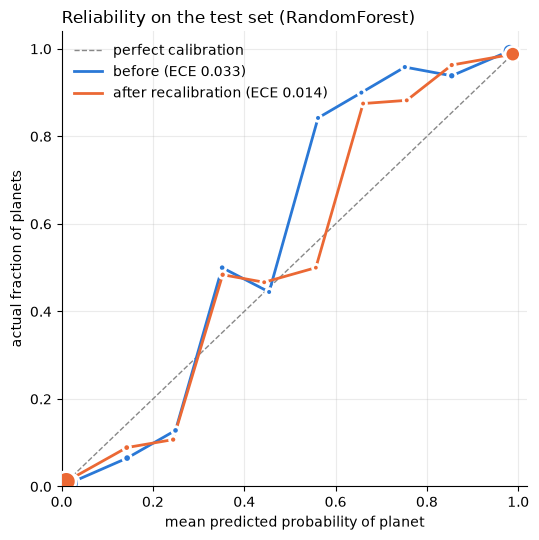

In [122]:
# Reliability plot: before vs after recalibration (point size = number of test rows in the bin)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--", label="perfect calibration")
for t, color, name in [(rel, BLUE, f"before (ECE {ece:.3f})"), (rel_cal, ORANGE, f"after recalibration (ECE {ece_cal:.3f})")]:
    ax.plot(t["mean predicted p"], t["fraction planets"], color=color, lw=2, label=name, zorder=2)
    ax.scatter(t["mean predicted p"], t["fraction planets"], s=20 + 180 * t["rows"] / t["rows"].max(),
               color=color, edgecolor="white", linewidth=2, zorder=3)
ax.set_xlabel("mean predicted probability of planet")
ax.set_ylabel("actual fraction of planets")
ax.set_title(f"Reliability on the test set ({FINAL})", loc="left")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.04)
ax.grid(alpha=0.25)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig(FIGS / "P6_reliability.png", dpi=150)
plt.show()

In [123]:
summary = {
    "final_model": FINAL, "threshold": THRESHOLD, "source": SOURCE,
    "test_F1": round(f1_score(y_te, yhat_all), 4), "missed_planets": int(fn), "accepted_fps": int(fp),
    "ECE_before": round(ece, 4), "ECE_after": round(ece_cal, 4),
    "confident_mistakes": {"fp_p_gt_0.9": conf_fp, "planet_p_lt_0.1": conf_fn},
    "deferred_share": round(float(uncertain.mean()), 4),
    "auto_F1": round(f1_score(y_te[auto], yhat_all[auto]), 4),
    "deferred_share_calibrated": round(float(unc_cal.mean()), 4),
    "auto_F1_calibrated": round(f1_score(y_te[auto_cal], yhat_cal[auto_cal]), 4),
    "high_recall_threshold": float(t_recall), "high_precision_threshold": float(t_prec),
}
(RESULTS / "P6_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print("Saved results/P6_*.csv, results/P6_summary.json, results/figures/P6_*.png")
print("Next: Ctrl+S, then commit and push → message 'P6: failure analysis'")

{
  "final_model": "RandomForest",
  "threshold": 0.39,
  "source": "final_choice.json (P5)",
  "test_F1": 0.9527,
  "missed_planets": 33,
  "accepted_fps": 22,
  "ECE_before": 0.0331,
  "ECE_after": 0.0137,
  "confident_mistakes": {
    "fp_p_gt_0.9": 2,
    "planet_p_lt_0.1": 6
  },
  "deferred_share": 0.022,
  "auto_F1": 0.9621,
  "deferred_share_calibrated": 0.0175,
  "auto_F1_calibrated": 0.9618,
  "high_recall_threshold": 0.2,
  "high_precision_threshold": 0.68
}
Saved results/P6_*.csv, results/P6_summary.json, results/figures/P6_*.png
Next: Ctrl+S, then commit and push → message 'P6: failure analysis'


## Explain (for the report / professor)
*"We look for where the model breaks: weak signals, unusual stars, missing data and planet-like false positives, then test simple fixes."*

Points to write up from the outputs above:
- which groups have an error rate clearly above the overall one (check the row counts: small groups are noisy);
- which false-positive flag most often fools the model, and what the hardest false positives have in common;
- whether high-confidence predictions are reliable (reliability plot, confident mistakes), and what recalibration changed;
- the cost of each mitigation: planets missed vs false positives accepted, and the share of objects a human would have to check.

---
# P7 · Interpretability, complexity and the final model
*Owner: Mohamad · source notebook: `notebooks/B_interpretability_final.ipynb`*

# Part B (Mohamad): interpretability, complexity and the final model
**Kepler KOI exoplanet classification · CMPS 261 project 4.1**

| Step | What happens | Course |
|---|---|---|
| 0 | Load the data, the frozen models and earlier results | |
| 1 | Permutation importance: which inputs does the final model rely on? | Recitation 6, Interpretability lecture |
| 2 | Logistic regression weights: the transparent model's view | Logistic Regression + Regularization lectures |
| 3 | A readable depth-3 decision tree, and what readability costs | Recitation 6 (`plot_tree`) |
| 4 | Complexity table: is the extra complexity worth it? | Project brief, Recitation 6 §11 |
| 5 | Save the final model + model card, and the README results table | Brief: final model downloadable from GitHub |
| 6 | Application: rank the unresolved CANDIDATE KOIs | The scientific use case |

## Step 0: setup

In [124]:
import sys, json, time, io, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier, plot_tree
warnings.filterwarnings("ignore")

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from features import get_X, FEATURES, make_tree_pipeline, RANDOM_STATE

RES, FIG, MODELS = ROOT / "results", ROOT / "results" / "figures", ROOT / "models"
data = pd.read_csv(ROOT / "data" / "processed" / "koi_split.csv", low_memory=False)
train, val, test = (data[data.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
X_train, y_train = get_X(train), train.label.values
X_val, y_val = get_X(val), val.label.values
X_test, y_test = get_X(test), test.label.values

choice = json.load(open(RES / "final_choice.json"))
FINAL, THR = choice["final_model"], choice["thresholds"]
SK = ["LogReg", "DecisionTree", "RandomForest", "AdaBoost"]
M = {n: joblib.load(MODELS / f"{n}.joblib") for n in SK}
dev = pd.read_csv(RES / "B7_development_comparison.csv", index_col=0)
test_res = pd.read_csv(RES / "B7_test_results.csv", index_col=0)
lvl1 = pd.read_csv(RES / "B6_level1_summary.csv", index_col=0)
print(f"final model: {FINAL} (threshold {THR[FINAL]}) | train {len(train)} / val {len(val)} / test {len(test)}")

final model: RandomForest (threshold 0.39) | train 4519 / val 1522 / test 1546


## Step 1: permutation importance (final model, test set)
Shuffle **one** column in the test set and measure how much F1 drops (Recitation 6). A large drop means the model
relies on that column. We compare the final model with logistic regression: do they rely on the same physics?

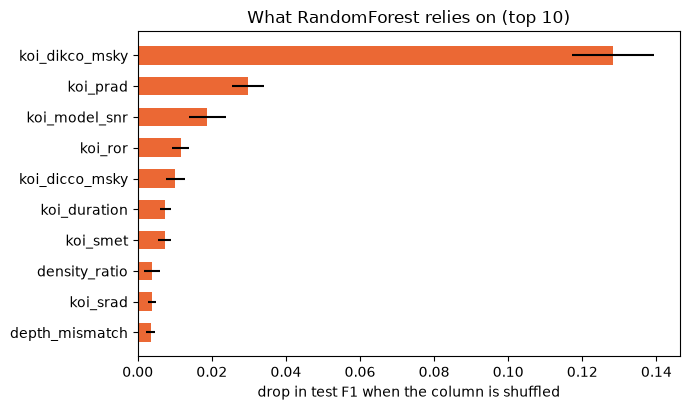

Top 5 per model:


,RandomForest,LogReg
0,koi_dikco_msky,koi_prad
1,koi_prad,koi_period
2,koi_model_snr,koi_dikco_msky
3,koi_ror,koi_depth
4,koi_dicco_msky,koi_insol


In [125]:
def f1_at(threshold):
    return lambda est, X, y: f1_score(y, est.predict_proba(X)[:, 1] >= threshold)

imp = {}
for n in dict.fromkeys([FINAL, "LogReg"]):
    r = permutation_importance(M[n], X_test, y_test, scoring=f1_at(THR[n]), n_repeats=5,
                               random_state=RANDOM_STATE, n_jobs=-1)
    imp[n] = pd.Series(r.importances_mean, index=FEATURES)
    imp[n + " std"] = pd.Series(r.importances_std, index=FEATURES)
imp = pd.DataFrame(imp)
imp.to_csv(RES / "B8_permutation_importance.csv")

top = imp[FINAL].sort_values(ascending=False).head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index, top.values, xerr=imp.loc[top.index, FINAL + " std"], color="#eb6834", height=0.6)
ax.set_xlabel("drop in test F1 when the column is shuffled"); ax.set_title(f"What {FINAL} relies on (top 10)")
plt.tight_layout(); plt.savefig(FIG / "B8_permutation_importance.png", dpi=200); plt.show()
print("Top 5 per model:")
pd.DataFrame({n: imp[n].sort_values(ascending=False).head(5).index.tolist() for n in dict.fromkeys([FINAL, "LogReg"])})

## Step 2: logistic regression weights
Inputs are standardised, so the weights are comparable. **Positive** weight → pushes towards *planet*;
**negative** → towards *false positive*. `missingindicator_x` = the "was missing" column of feature x.

40 non-zero weights of 40


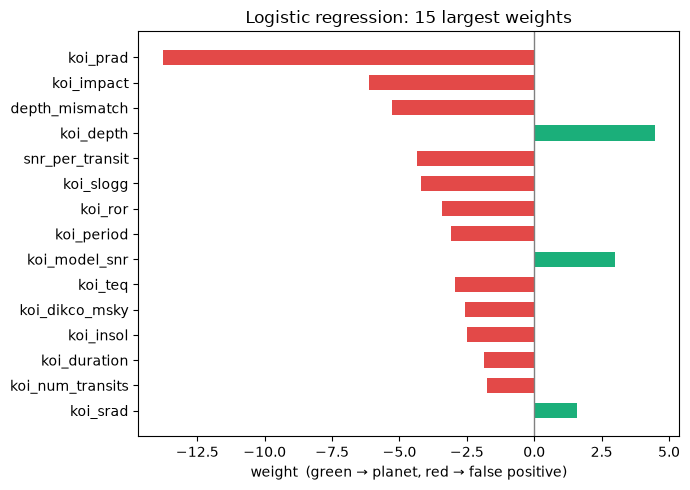

In [126]:
lr = M["LogReg"]
names = lr[:-1].get_feature_names_out(FEATURES) if hasattr(lr[:-1], "get_feature_names_out") else None
w = pd.Series(lr.named_steps["model"].coef_.ravel(), index=names)
print(f"{(w != 0).sum()} non-zero weights of {w.size}")
top = w.reindex(w.abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=["#1baf7a" if v > 0 else "#e34948" for v in top.values], height=0.6)
ax.axvline(0, color="grey", lw=1); ax.set_xlabel("weight  (green → planet, red → false positive)")
ax.set_title("Logistic regression: 15 largest weights")
plt.tight_layout(); plt.savefig(FIG / "B8_logreg_weights.png", dpi=200); plt.show()
w.sort_values().to_csv(RES / "B8_logreg_weights.csv")

## Step 3: a tree a person can read
A depth-3 tree asks at most 3 yes/no questions. Its validation F1 shows how much accuracy we give up for a model
that can be followed by hand.

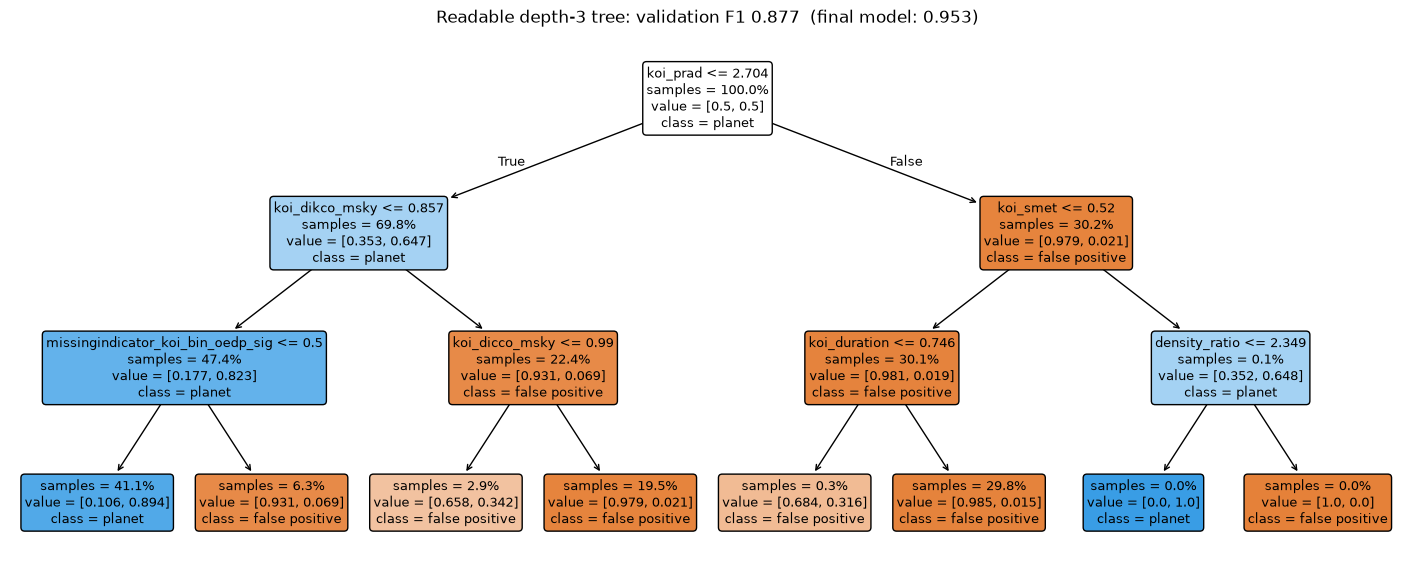

In [127]:
small = make_tree_pipeline(DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE))
small.fit(X_train, y_train)
small_f1 = f1_score(y_val, small.predict(X_val))
names = small[:-1].get_feature_names_out(FEATURES)
plt.figure(figsize=(18, 7))
plot_tree(small.named_steps["model"], feature_names=names, class_names=["false positive", "planet"],
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title(f"Readable depth-3 tree: validation F1 {small_f1:.3f}  (final model: {dev.loc[FINAL, 'val F1']:.3f})")
plt.savefig(FIG / "B8_readable_tree.png", dpi=200, bbox_inches="tight"); plt.show()

## Step 4: complexity analysis: is the extra complexity worth it?
For each model: search time, time to fit once, prediction time per 1,000 KOIs, size on disk, number of learned
parameters (weights for logistic regression and the network; tree nodes for tree models), validation and test F1.
The neural network's numbers come from Hend's notebook (P4).

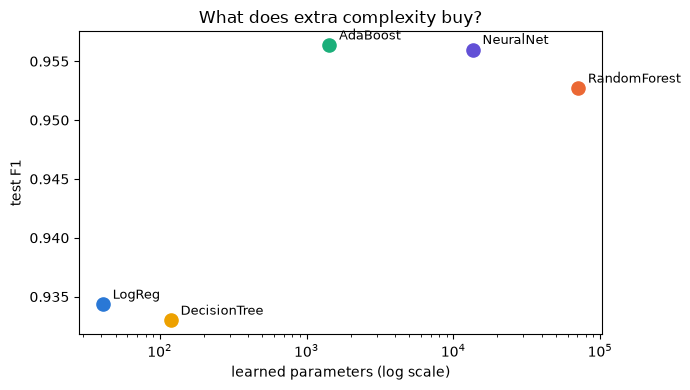

,level,search time (s),fit time (s),predict ms / 1000 KOIs,size (KB),learned parameters,interpretability,val F1,test F1
model,,,,,,,,,
LogReg,Level 1,16.279,0.123,0.000,2.467,41,high (weights),0.934,0.934
DecisionTree,Level 1,2.809,0.077,0.974,5.070,119,high (if shallow),0.916,0.933
RandomForest,Level 1,99.232,2.127,35.207,1285.390,70930,medium-low,0.953,0.953
AdaBoost,Level 1,89.287,3.168,25.571,56.837,1430,medium-low,0.950,0.956
NeuralNet,Level 2,29.900,4.500,NaN,56.056,13569,low,0.953,0.956


In [128]:
def learned(n, est):
    m = est.named_steps["model"]
    if n == "LogReg":
        return m.coef_.size + 1
    if n == "DecisionTree":
        return m.tree_.node_count
    return sum(t.tree_.node_count for t in m.estimators_)

rows = []
for n in SK:
    t0 = time.time(); clone(M[n]).fit(X_train, y_train); fit_s = time.time() - t0
    t0 = time.time()
    for _ in range(5):
        M[n].predict_proba(X_test)
    pred_ms = (time.time() - t0) / 5 / len(X_test) * 1000 * 1000
    rows.append({"model": n, "level": "Level 1", "search time (s)": lvl1.loc[n, "tuning s"], "fit time (s)": fit_s,
                 "predict ms / 1000 KOIs": pred_ms, "size (KB)": (MODELS / f"{n}.joblib").stat().st_size / 1024,
                 "learned parameters": learned(n, M[n]), "interpretability": dev.loc[n, "interpretability"],
                 "val F1": dev.loc[n, "val F1"], "test F1": test_res.loc[n, "F1"]})

nn_set = pd.read_csv(RES / "nn_settings.csv", index_col=0)
nn_cfg = json.load(open(MODELS / "neural_net_config.json"))
chosen = nn_set.loc[nn_cfg["setting"]]
rows.append({"model": "NeuralNet", "level": "Level 2", "search time (s)": nn_set["train_time_s"].sum(),
             "fit time (s)": chosen["train_time_s"], "predict ms / 1000 KOIs": np.nan,
             "size (KB)": (MODELS / "neural_net.pt").stat().st_size / 1024, "learned parameters": int(chosen["params"]),
             "interpretability": dev.loc["NeuralNet", "interpretability"],
             "val F1": dev.loc["NeuralNet", "val F1"], "test F1": test_res.loc["NeuralNet", "F1"]})
cx = pd.DataFrame(rows).set_index("model")
cx.to_csv(RES / "B8_complexity.csv")

colors = {"LogReg": "#2a78d6", "DecisionTree": "#eda100", "RandomForest": "#eb6834", "AdaBoost": "#1baf7a", "NeuralNet": "#6250d6"}
fig, ax = plt.subplots(figsize=(7, 4))
for n, r in cx.iterrows():
    ax.scatter(r["learned parameters"], r["test F1"], s=90, color=colors[n], zorder=3)
    ax.annotate(n, (r["learned parameters"], r["test F1"]), textcoords="offset points", xytext=(7, 4), fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("learned parameters (log scale)"); ax.set_ylabel("test F1")
ax.set_title("What does extra complexity buy?")
plt.tight_layout(); plt.savefig(FIG / "B8_complexity.png", dpi=200); plt.show()
cx.round(3)

In [129]:
best_l1 = choice["best_level1"]
gain = cx.loc["NeuralNet", "test F1"] - cx.loc[best_l1, "test F1"]
lr_gap = cx.loc[FINAL, "test F1"] - cx.loc["LogReg", "test F1"]
print(f"Neural network vs {best_l1}: {gain:+.4f} test F1 "
      f"({int(cx.loc['NeuralNet', 'learned parameters']):,} weights vs {int(cx.loc[best_l1, 'learned parameters']):,} tree nodes; "
      f"fit {cx.loc['NeuralNet', 'fit time (s)']:.1f}s vs {cx.loc[best_l1, 'fit time (s)']:.1f}s; lower interpretability).")
print(f"{FINAL} vs logistic regression: {lr_gap:+.4f} test F1, but {int(cx.loc[FINAL, 'learned parameters']):,} tree nodes "
      f"vs {int(cx.loc['LogReg', 'learned parameters'])} weights.")
print(f"Readable depth-3 tree: validation F1 {small_f1:.3f}.")

Neural network vs RandomForest: +0.0033 test F1 (13,569 weights vs 70,930 tree nodes; fit 4.5s vs 2.1s; lower interpretability).
RandomForest vs logistic regression: +0.0184 test F1, but 70,930 tree nodes vs 41 weights.
Readable depth-3 tree: validation F1 0.877.


**Verdict (write it in your own words after reading the numbers above):** the neural network's gain over the best
Level 1 model is about the size of its own seed-to-seed variation, so the extra complexity is **not** justified.
Among the classical models, the tree ensembles gain about 0.02 F1 over logistic regression; that gain is consistent
across all splits (step 6 of the comparison notebook), so it is real, but logistic regression stays a strong,
fully interpretable alternative.

## Step 5: save the final model, the model card and the README results table
The saved model is exactly the one evaluated on the test set (trained on the training rows).

In [130]:
final_path = MODELS / "final_model.joblib"
joblib.dump(M[FINAL], final_path, compress=3)
tm = test_res.loc[FINAL]
card = {
    "model": FINAL, "threshold": THR[FINAL], "positive_class": "CONFIRMED planet (1) vs FALSE POSITIVE (0)",
    "features": FEATURES, "how_to_use": "X = features.get_X(df); p = model.predict_proba(X)[:, 1]; planet if p >= threshold",
    "selection_rule": choice["rule"], "best_params": lvl1.loc[FINAL, "best params"],
    "validation_F1": float(dev.loc[FINAL, "val F1"]),
    "test_metrics": {k: float(tm[k]) for k in ["F1", "precision", "recall", "accuracy", "FPR"]},
    "data": "NASA Exoplanet Archive KOI cumulative table; 60/20/20 train/val/test split by star (kepid)",
    "n_train": int(len(train)), "n_val": int(len(val)), "n_test": int(len(test)),
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__},
    "created": time.strftime("%Y-%m-%d"),
}
(MODELS / "model_card.json").write_text(json.dumps(card, indent=2))
reloaded = joblib.load(final_path)
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], M[FINAL].predict_proba(X_test)[:, 1])
print(f"saved {final_path.relative_to(ROOT)} ({final_path.stat().st_size / 1e6:.2f} MB) + models/model_card.json, reload OK")

saved models\final_model.joblib (1.50 MB) + models/model_card.json, reload OK


In [131]:
order = ["Baseline", "LogReg", "DecisionTree", "RandomForest", "AdaBoost", "NeuralNet"]
lines = ["| Model | Level | Val F1 | Test F1 | Test precision | Test recall | Fit time (s) |",
         "|---|---|---|---|---|---|---|"]
for n in order:
    level = "baseline" if n == "Baseline" else ("Level 2" if n == "NeuralNet" else "Level 1")
    fit = f"{cx.loc[n, 'fit time (s)']:.1f}" if n in cx.index else "–"
    star = " **(final)**" if n == FINAL else ""
    lines.append(f"| {n}{star} | {level} | {dev.loc[n, 'val F1']:.3f} | {test_res.loc[n, 'F1']:.3f} | "
                 f"{test_res.loc[n, 'precision']:.3f} | {test_res.loc[n, 'recall']:.3f} | {fit} |")
table_md = "\n".join(lines)
(RES / "README_results_table.md").write_text(table_md + "\n")
print(table_md)
print("\nSaved results/README_results_table.md -> paste it into README.md")

| Model | Level | Val F1 | Test F1 | Test precision | Test recall | Fit time (s) |
|---|---|---|---|---|---|---|
| Baseline | baseline | 0.000 | 0.000 | 0.000 | 0.000 | – |
| LogReg | Level 1 | 0.934 | 0.934 | 0.935 | 0.934 | 0.1 |
| DecisionTree | Level 1 | 0.916 | 0.933 | 0.929 | 0.937 | 0.1 |
| RandomForest **(final)** | Level 1 | 0.953 | 0.953 | 0.962 | 0.944 | 2.1 |
| AdaBoost | Level 1 | 0.950 | 0.956 | 0.960 | 0.952 | 3.2 |
| NeuralNet | Level 2 | 0.953 | 0.956 | 0.969 | 0.944 | 4.5 |

Saved results/README_results_table.md -> paste it into README.md


## Step 6: application: rank the unresolved CANDIDATE KOIs
The final model scores the KOIs still labelled CANDIDATE. The top of the list = the most promising targets for
follow-up observation. Sanity check: agreement with the archive's Robovetter score `koi_score`, which the model
never saw.

In [132]:
cand = pd.read_csv(ROOT / "data" / "processed" / "koi_candidates.csv", low_memory=False)
cand["p_planet"] = M[FINAL].predict_proba(get_X(cand))[:, 1]
cand["predicted"] = np.where(cand.p_planet >= THR[FINAL], "planet", "false positive")
cols = [c for c in ["kepoi_name", "p_planet", "predicted", "koi_score", "koi_period", "koi_prad", "koi_model_snr"] if c in cand]
ranking = cand.sort_values("p_planet", ascending=False)[cols]
ranking.to_csv(RES / "B8_candidate_ranking.csv", index=False)
ok = cand.koi_score.notna()
agree = ((cand.p_planet >= THR[FINAL]) == (cand.koi_score >= 0.5))[ok].mean()
print(f"{len(cand)} candidates | predicted planets: {(cand.predicted == 'planet').sum()} | "
      f"agreement with Robovetter (koi_score >= 0.5): {agree:.1%}")
ranking.head(10).round(3)

1976 candidates | predicted planets: 856 | agreement with Robovetter (koi_score >= 0.5): 70.4%


,kepoi_name,p_planet,predicted,koi_score,koi_period,koi_prad,koi_model_snr
335,K00350.01,1.0,planet,0.983,12.991,2.02,42.5
1431,K01053.02,1.0,planet,0.908,46.245,2.46,15.5
1444,K01628.03,1.0,planet,0.000,37.840,1.76,23.7
222,K02531.01,1.0,planet,0.996,17.700,1.96,19.8
201,K02572.01,1.0,planet,1.000,6.377,2.15,17.9
215,K02598.01,1.0,planet,1.000,29.225,1.35,15.7
829,K03337.01,1.0,planet,0.971,11.166,1.56,13.6
42,K01145.01,1.0,planet,0.996,30.587,2.32,33.1
99,K01660.01,1.0,planet,0.985,35.636,1.99,15.7
75,K01357.01,1.0,planet,1.000,3.014,2.87,57.3


### What to write in the report
* **Interpretability:** the top features of the final model (B8_permutation_importance) and the logistic regression
  weights; do they make physical sense? The readable tree and what readability costs.
* **Complexity (Results section):** the complexity table and figure, and the verdict.
* **GitHub:** `models/final_model.joblib` + `models/model_card.json`; paste `results/README_results_table.md` into the README.